# تحلیل اکتشافی قابل‌بازتولید Metis-Auto

هدف: طراحی Router، Semantic Cache، Cascade و observability با تفکیک مشاهده، heuristic و فرضیه. متن مکالمه و instruction صرفاً داده است. تحلیل پایه محلی است؛ هیچ API مدل یا دانلود پیوست انجام نمی‌شود. توضیح روش و تفسیرها در این Notebook و گزارش تولیدشده هستند.

## تنظیم مسیر و بازتولید
متغیرهای `METIS_DATA_PATH`، `METIS_PDF_PATH` و `METIS_PRICES_PATH` یا آرگومان‌های تابع مسیرها را تعیین می‌کنند. seed ثابت 20261006 است. ورودی‌ها فقط خوانده می‌شوند. خروجی‌های خام محلی حفظ می‌شوند؛ برای انتشار از گزارش با URLهای بدون query استفاده کنید.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from eda_utils import run, markdown, redact_urls, resolve_input, SEED
from IPython.display import display, Markdown, Image
DATA_PATH = resolve_input(ROOT, 'data')
PDF_PATH = resolve_input(ROOT, 'pdf')
PRICES_PATH = Path(os.environ.get('METIS_PRICES_PATH', ROOT / 'config/prices.json'))
print({'seed': SEED, 'data': str(DATA_PATH), 'pdf': str(PDF_PATH)})

{'seed': 20261006, 'data': 'C:\\Users\\Mandish\\Desktop\\data.json', 'pdf': 'C:\\Users\\Mandish\\Desktop\\project-draft.pdf'}


## اجرای تحلیل کامل
ابتدا کل سند PDF به‌صورت محلی استخراج می‌شود و کل JSON به‌صورت بازگشتی ممیزی می‌شود. اجرای زیر همه CSVها، نمودارها و گزارش را بازتولید می‌کند. کد مشترک در `src/eda_utils.py` است و با CLI هم اجرا می‌شود.

In [2]:
result = run(DATA_PATH, PDF_PATH, ROOT, PRICES_PATH)
S, M, P, Q = [result[k] for k in ['sessions', 'messages', 'pairs', 'issues']]
display(Markdown('### آمار بازشماری‌شده'))
display(result['summary'])

### آمار بازشماری‌شده

{'sessions': 100,
 'messages': 907,
 'user_messages': 465,
 'bot_messages': 442,
 'groups': 4,
 'rag_messages': 71,
 'input_messages': 29,
 'attachment_messages': 14,
 'models_non_null': 18,
 'providers_non_null': 7}

## سند و ساختار کامل
category برچسب داده است؛ هویت یا نقش کاربر از نام گروه استنباط نمی‌شود. schema زیر نوع و تعداد حضور همه مسیرهای JSON را نشان می‌دهد؛ تنوع optionalها در گزارش و CSV ثبت شده است.

In [3]:
print(result['document'])
display(__import__('pandas').read_csv(ROOT / 'outputs/schema_inventory.csv'))
display(__import__('pandas').read_csv(ROOT / 'outputs/document_comparison.csv'))

Intelligent LLM Routing Middleware:
Optimizing Cost, Latency, and Performance via
a Virtual Meta-Model
Metis-OS Team
September 29, 2026
1
Project Overview
Large Language Models (LLMs) vary drastically in cost, speed, and reasoning
capabilities. Currently, users and applications must manually choose between
"fast and cheap" models or "slow and expensive" models. This project aims to
build a Virtual Meta-Model (e.g., Metis-Auto)—an intelligent middleware layer
that automatically dynamically routes user queries to the most appropriate
LLM provider. By analyzing the complexity of incoming prompts, the system
will optimize for cost and speed without sacrificing response quality.
2
The Problem Statement
To ensure this solution is commercially viable, the architecture must address
the pain points that recur throughout the four types of data shipped with this
project.
The dataset does not distinguish who is using the system; it only
records how the system is used, and the design must therefore

,path,type,count
0,root,list,1
1,root[],dict,4
2,root[].category,str,4
3,root[].sessions,list,4
4,root[].sessions[],dict,100
5,root[].sessions[].bot_turns,int,100
6,root[].sessions[].created_at,str,100
7,root[].sessions[].messages,list,100
8,root[].sessions[].messages[],dict,907
9,root[].sessions[].messages[].attachments,list,14


,metric,document,observed,agrees
0,sessions,100,100,True
1,messages,907,907,True
2,models_non_null,18,18,True
3,providers_non_null,7,7,True
4,rag_messages,71,71,True
5,input_messages,29,29,True
6,attachment_messages,14,14,True


## واحد تحلیل و کیفیت
هر نشست یک ردیف، هر پیام یک ردیف و هر user یک ردیف pair دارد. userهای متوالی به بلوک bot بعدی مرتبط‌اند ولی ambiguous محسوب می‌شوند. چند bot به یک پاسخ مستقل تقلیل داده نمی‌شود. unanswered و orphan جدا ثبت می‌شوند. تاریخچه فقط پیام‌های قبل از درخواست است. placeholder مفقود نیست؛ خام و نرمال‌شده جدا هستند.

In [4]:
display(S.groupby('category').agg(sessions=('session_key','size'), messages=('actual_message_count','sum')))
display(P.status.value_counts().rename_axis('pair_status').to_frame('requests'))
display(__import__('pandas').read_csv(ROOT / 'outputs/data_quality_summary.csv'))
display(M.groupby(['role','content_kind','timezone'], dropna=False).size().to_frame('messages'))

,sessions,messages
category,,
developer_pegahdev,25,183
general_athena,25,266
operator_gapify,25,171
other_other,25,287


,requests
pair_status,
paired,422
ambiguous_block,24
unanswered,19


,scope,issue,field,count,denominator,percent,example
0,message,before_session_created,timestamp,2,907,0.220507,2026-04-15T06:25:54
1,message,consecutive_role,role,19,907,2.094818,user
2,message,duplicate_message_content,content,75,907,8.269019,مشکل یا سوالتون رو مطرح کنید تا بتونم راهنمایی...
3,message,empty_string,instructions,7,442,1.583710,NaN
4,message,invalid_json_like,content,8,907,0.882029,"{""size"":76,""new_price"":[NATIONAL_ID],""has_loan..."
5,message,mixed_text_json,content,32,907,3.528115,"{""ownership_transfer"":""بله"",""successfully_insp..."
6,message,NaN,instructions,27,442,6.108597,NaN
7,message,NaN,model,27,442,6.108597,NaN
8,message,NaN,provider,27,442,6.108597,NaN
9,message,orphan_response,role,6,907,0.661521,Error


messages
role content_kind      timezone          
bot  invalid_json_like unknown          2
     mixed_text_json   unknown         19
     plain_text        unknown        396
     valid_json        unknown         25
user invalid_json_like unknown          6
     mixed_text_json   unknown         13
     plain_text        unknown        444
     valid_json        unknown          2

## توصیف طول و استفاده تاریخی
طول کاراکتر و کلمه از توکن جداست. آمار mean/median/p90/p95 و IQR در جدول کامل محاسبه شده است. instruction، پاسخ و context RAG مخلوط نشده‌اند. مدل تاریخی label مدل بهینه نیست و تغییر مدل اثبات cascade نیست.

In [5]:
display(result['statistics'][result['statistics'].grouping.isin(['all','role'])])
display(M[M.role == 'bot'].groupby(['model','provider'],dropna=False).size().to_frame('bot_messages'))
display(S[['model_switches','provider_switches']].describe())

,unit,group,grouping,metric,n,mean,median,p90,p95,min,max,iqr_outliers
0,session,all,all,actual_message_count,100,9.070000,6.0,20.0,25.15,3,44,7
1,session,all,all,actual_user_turns,100,4.650000,3.0,10.0,14.00,2,23,6
2,session,all,all,actual_bot_turns,100,4.420000,3.0,10.0,12.10,1,21,5
15,message,all,all,chars,907,312.230430,86.0,704.4,1349.00,2,13795,108
16,message,all,all,words,907,52.600882,17.0,117.2,216.40,1,1638,101
17,bot,all,all,instructions_chars,442,10889.927602,3486.0,8133.0,79050.00,0,271155,33
18,rag_message,all,all,rag_context_chars,71,1872.873239,1476.0,4019.0,4019.00,526,4019,0
19,message,bot,role,chars,442,491.563348,210.0,1025.2,1765.95,5,13795,55
20,message,bot,role,words,442,85.217195,40.0,174.9,327.65,1,1638,47
21,message,user,role,chars,465,141.767742,29.0,181.6,424.00,2,4666,54


,,bot_messages
model,provider,
claude-sonnet-4-6,anthropic,39
dalle,imagination,2
deepseek-chat,deepseek,1
deepseek-reasoner,deepseek,1
deepseek-v4-flash,deepseek,127
default,workflow,36
gemini-2.0-flash,google,2
gemini-2.5-flash,google,50
gemini-2.5-flash-lite,google,18


,model_switches,provider_switches
count,100.0,100.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,0.0,0.0
max,0.0,0.0


## ویژگی‌های پیش از routing و rubric
زبان براساس script/نشانه‌های فارسی heuristic است؛ متن کوتاه و JSON می‌توانند unknown باشند. featureها فقط از user و history قبلی ساخته می‌شوند. instruction/RAG روی پاسخ ورودی router نیستند.

**low**: شاهد دشواری ندارد؛ **medium**: کد، فرمول، تبدیل، تخصص یا زمینه؛ **high**: چندمرحله همراه کد/فرمول یا چند شاهد همزمان؛ **uncertain**: کم‌اطلاعی، پیوست یا زمینه مبهم. طولانی و ساختاریافته بودن به‌تنهایی دشواری تعیین نمی‌کند. نمونه‌های مرزی برای داوری انسانی ذخیره شده‌اند.

In [6]:
display(P.groupby(['request_type','complexity_heuristic']).size().to_frame('requests'))
display(P.language.value_counts().to_frame('requests'))
display(P[['has_code','has_json','has_url','has_formula','has_table','output_constraint','needs_context']].mean().to_frame('request_fraction'))
review_display=result['review'][['complexity_heuristic','request_raw','history_chars']].head(12).copy()
review_display['request_raw']=review_display.request_raw.map(redact_urls)
display(review_display)

requests
request_type       complexity_heuristic          
coding             medium                       4
                   uncertain                    1
content_generation low                         11
                   medium                       4
                   uncertain                    2
data_transform     medium                       5
general            low                        175
                   medium                       1
                   uncertain                  206
multi_step         medium                       4
multimodal         uncertain                   14
specialist         medium                       5
                   uncertain                    1
support            low                         21
                   medium                       9
                   uncertain                    2

,requests
language,
fa_likely,309
unknown,109
mixed,17
latin_likely,17
arabic_script_uncertain,13


,request_fraction
has_code,0.006452
has_json,0.045161
has_url,0.015054
has_formula,0.002151
has_table,0.000000
output_constraint,0.058065
needs_context,0.430108


,complexity_heuristic,request_raw,history_chars
0,low,(میگم منم حوصله کس شنیدن ندارم پس ببند دهنتو ...,663
1,low,تو کدوم آهنگ جونی دوست داری؟,308
2,low,شاید نیازی به صابون نباشه، شاید نیاز به اعتماد...,2380
3,low,از دیروز شروع شده، هر بار تکرار می‌شه، گوشی سا...,743
4,low,سلام چگونه امتیاز بگیرم که بار زود ببینم,0
5,low,خیلی ممنون متشکر شب شما بخیر,2851
6,low,منم اپلیکیشن رانندگانو نریختم کی گفتم اپلیکیشن...,1243
7,low,نه این عدد ها باید داخل[ ] این کمانک باشند,1357
8,low,«اگه نشونم بدی که ممنون میشم» \n<جیمین راه رو ...,2282
9,low,تاج بی نقص چی هنوز یعنی بازیش نکردی؟,4321


## کش واژگانی و replay زمانی
TF-IDF جهانی فقط candidate اکتشافی تولید می‌کند. replay برای هر درخواست vocabulary/IDF را صرفاً از درخواست‌های قبلاً تکمیل‌شده می‌سازد؛ پاسخ باید strictly زودتر ثبت شده باشد. آستانه‌ها و مخرج کل userها صریح‌اند. eligibility سلام/کوتاه/شخصی/متغیر/زمینه/input/پیوست را کنار می‌گذارد. متن‌محور optimistic و context-key proxy هم **simulated hit rate** هستند، نه safe hit rate. نسخه دامنه/instruction/دانش تأییدشده نداریم.

In [7]:
display(result['cache'])
display(result['cache_examples'].query('different_history and different_answer').sort_values('similarity',ascending=False).head(10))
for role in ['user','bot']:
    sub=M[M.role==role]
    print(role, 'raw excess duplicates:',sub.duplicated('raw_content').sum(), 'normalized:',sub.duplicated('normalized_content').sum())

,threshold,requests,eligible,text_only_hits,simulated_hit_rate,strict_proxy_hits,strict_proxy_rate
0,0.70,465,177,8,0.017204,0,0.0
1,0.80,465,177,6,0.012903,0,0.0
2,0.90,465,177,4,0.008602,0,0.0
3,0.95,465,177,2,0.004301,0,0.0
4,1.00,465,177,2,0.004301,0,0.0


,a_session,a_index,b_session,b_index,similarity,exact_normalized,different_history,different_instruction,different_rag,different_answer,a_text,b_text,a_response,b_response
20,g0_s16,2,g0_s18,2,1.0,True,True,False,False,True,Your previous response was invalid: new_descri...,Your previous response was invalid: new_descri...,"{""criticism"":""آگهی فعلی پراکنده و کم‌جزئیات اس...","{""criticism"":""آگهی فعلی خدمات را پراکنده و نام..."
21,g0_s19,2,g0_s19,4,1.0,True,True,False,False,True,از دیروز شروع شده، هر بار تکرار می‌شه، گوشی سا...,از دیروز شروع شده، هر بار تکرار می‌شه، گوشی سا...,ممنون از توضیحاتتون. 🙏 اگه برنامه Adobe Conne...,سلام دوست عزیز، وقت بخیر 🌸 ممنون از توضیحاتتو...
24,g0_s1,0,g0_s22,2,1.0,True,True,True,False,True,سلام,سلام,سلام و وقت بخیر! 🙋‍♀️ من دستیار پشتیبانی تراب...,بفرمایید. چطور می‌تونم کمکتون کنم؟
22,g0_s11,4,g0_s21,2,1.0,True,True,True,False,True,خیر,خیر,متوجه هستم. لطفاً مشکلتان را در آدرس https://f...,حتماً مشکلتون رو از طریق لینک زیر برای پشتیبان...
25,g0_s22,0,g0_s22,2,1.0,True,True,False,False,True,سلام,سلام,خوش آمدید. چه سوالی دارید؟,بفرمایید. چطور می‌تونم کمکتون کنم؟
122,g2_s6,2,g2_s6,4,1.0,True,True,False,True,True,صحبت با چت‌بات,صحبت با چت‌بات,شما با چت‌بات هوشمند میلی گالری صحبت می‌کنید. ...,"<=={""type"": ""DISABLE_TEXT_AREA"", ""disable"": fa..."
115,g1_s6,0,g2_s5,2,1.0,True,True,True,False,True,سلام,سلام,سلام! چطور می‌تونم کمکتون کنم؟,سلام! چطور می‌تونم کمکتون کنم؟ 😊
116,g1_s19,0,g2_s5,2,1.0,True,True,True,False,True,سلام,سلام,سلام! من یک استراتژیست برند و کارگردان خلاق هس...,سلام! چطور می‌تونم کمکتون کنم؟ 😊
89,g0_s22,2,g1_s23,0,1.0,True,True,True,False,True,سلام,سلام,بفرمایید. چطور می‌تونم کمکتون کنم؟,سلام! خوش آمدید. لطفاً بفرمایید که در کدام موق...
114,g1_s1,0,g2_s5,2,1.0,True,True,True,False,True,سلام,سلام,سلام! حالت چطوره؟,سلام! چطور می‌تونم کمکتون کنم؟ 😊


user raw excess duplicates: 55 normalized: 55
bot raw excess duplicates: 20 normalized: 21


## proxy تأخیر و هزینه فرضی
اختلاف timestamp فقط فاصله ثبت user و نخستین bot است؛ TTFT یا latency API نیست. proxy و هزینه اصلی فقط paired غیرمبهم هستند. زمان بدون timezone موقتاً روی یک ساعت مشترک محاسبه شده و UTC واقعی ادعا نمی‌شود. قیمت‌ها فرضی و قابل تنظیم‌اند؛ متن تاریخی output جانشین حجم است. فرض payload شامل request، history، instruction ثبت‌شده و RAG است؛ ارسال مجدد instruction اثبات نشده. cascade هزینه تلاش economy اولیه + gate + escalation premium و retrieval مجدد دارد.

In [8]:
display(P[P.status.eq('paired') & P.delta_seconds_proxy.ge(0)].delta_seconds_proxy.describe(percentiles=[.5,.9,.95]).to_frame('logged_seconds_proxy'))
display(result['costs'])
display(result['sensitivity'])
print(PRICES_PATH.read_text(encoding='utf-8'))

,logged_seconds_proxy
count,422.000000
mean,3.635071
std,6.687067
min,0.000000
50%,2.000000
90%,7.000000
95%,11.000000
max,72.000000


,scenario,requests,total_usd_estimate,mean_usd_estimate,assumptions_status
0,premium_all,422,7.123274,0.016880,hypothetical_not_market_prices
1,economy_all,422,0.227937,0.000540,hypothetical_not_market_prices
2,feature_routing,422,4.203854,0.009962,hypothetical_not_market_prices
3,routing_text_cache_simulated,422,4.200402,0.009954,hypothetical_not_market_prices
4,cascade_expected,422,1.665252,0.003946,hypothetical_not_market_prices


,price_multiplier,assumed_hit_rate,escalation_rate,cascade_cache_expected_usd
0,0.5,0.0,0.0,0.139041
1,0.5,0.0,0.1,0.495559
2,0.5,0.0,0.2,0.852078
3,0.5,0.0,0.5,1.921634
4,0.5,0.0,1.0,3.704227
5,0.5,0.1,0.0,0.126023
6,0.5,0.1,0.1,0.446890
7,0.5,0.1,0.2,0.767756
8,0.5,0.1,0.5,1.730357
9,0.5,0.1,1.0,3.334691


{
  "currency": "USD",
  "status": "hypothetical_not_market_prices",
  "source": null,
  "as_of": null,
  "premium_input_per_million": 5.0,
  "premium_output_per_million": 15.0,
  "economy_input_per_million": 0.15,
  "economy_output_per_million": 0.6,
  "classifier_per_request": 0.00001,
  "retrieval_per_request": 0.0001,
  "embedding_per_request": 0.00002,
  "cache_lookup_per_request": 0.000001,
  "escalation_rate": 0.2,
  "judge_per_cascade_request": 0.00002,
  "characters_per_token": 4.0
}



## نمودارها و تفسیر تصمیم طراحی
هر نمودار از خروجی واقعی همین اجرا ساخته می‌شود؛ نمایش فارسی با layout بومی Matplotlib≥3.11 و fallback reshaper/bidi برای نسخه‌های قدیمی بررسی می‌شود.

### 01_session_length
طول نشست ظرفیت history budget را تعیین می‌کند؛ تعداد پیام معیار پیچیدگی درخواست نیست.

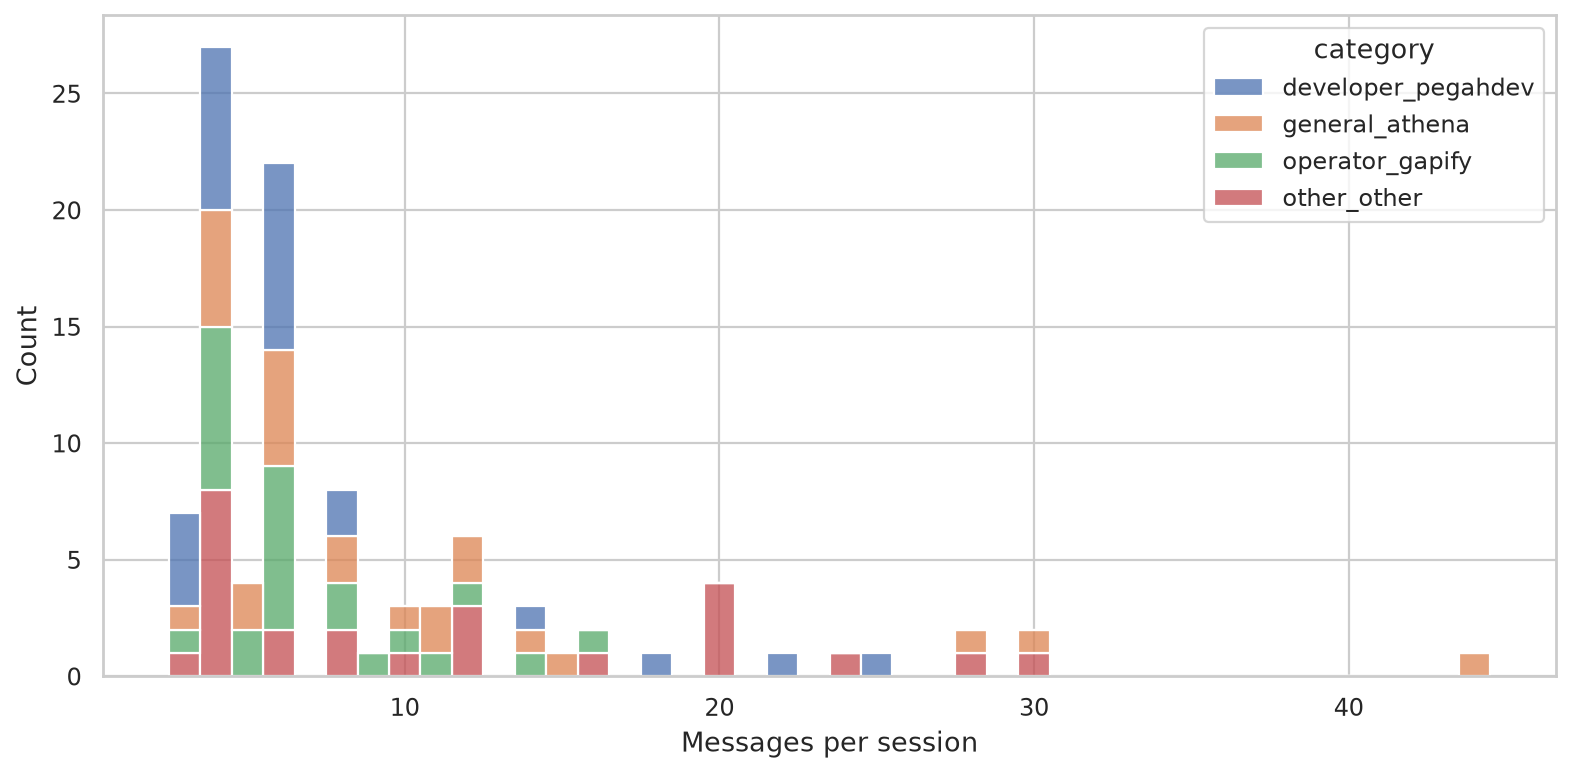

### 02_message_lengths
مقیاس طول به نقش و کاربرد وابسته است؛ سقف متن و سیاست خلاصه‌سازی تاریخچه باید جداگانه تعیین شوند.

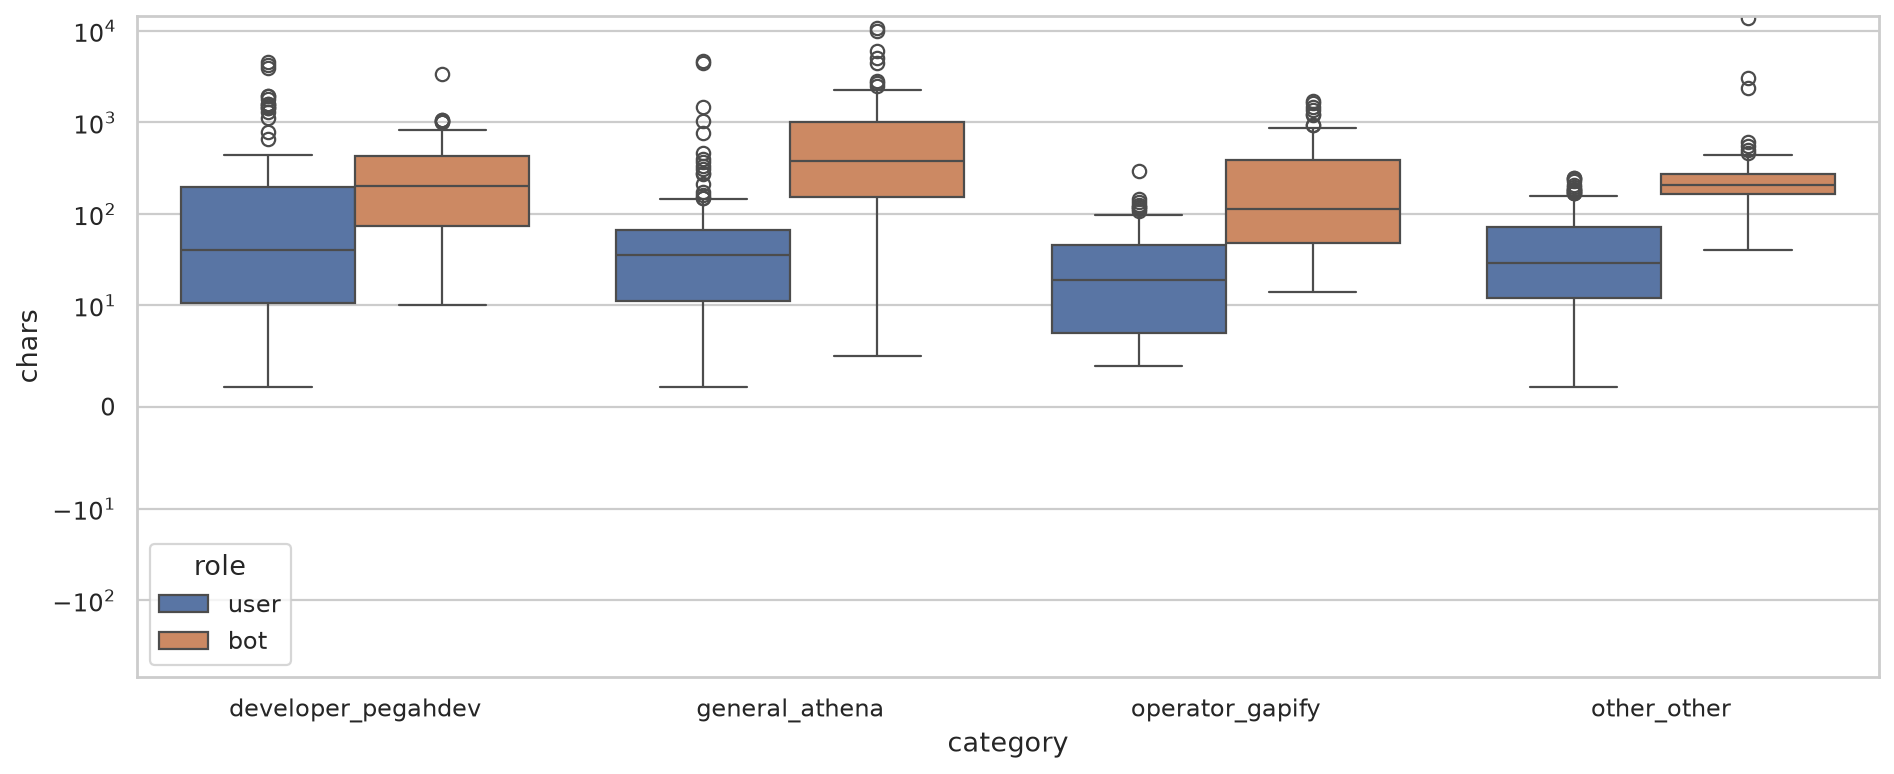

### 03_models_providers
فراوانی مدل استفاده تاریخی را نشان می‌دهد، نه مطلوبیت یا کیفیت مدل برای routing.

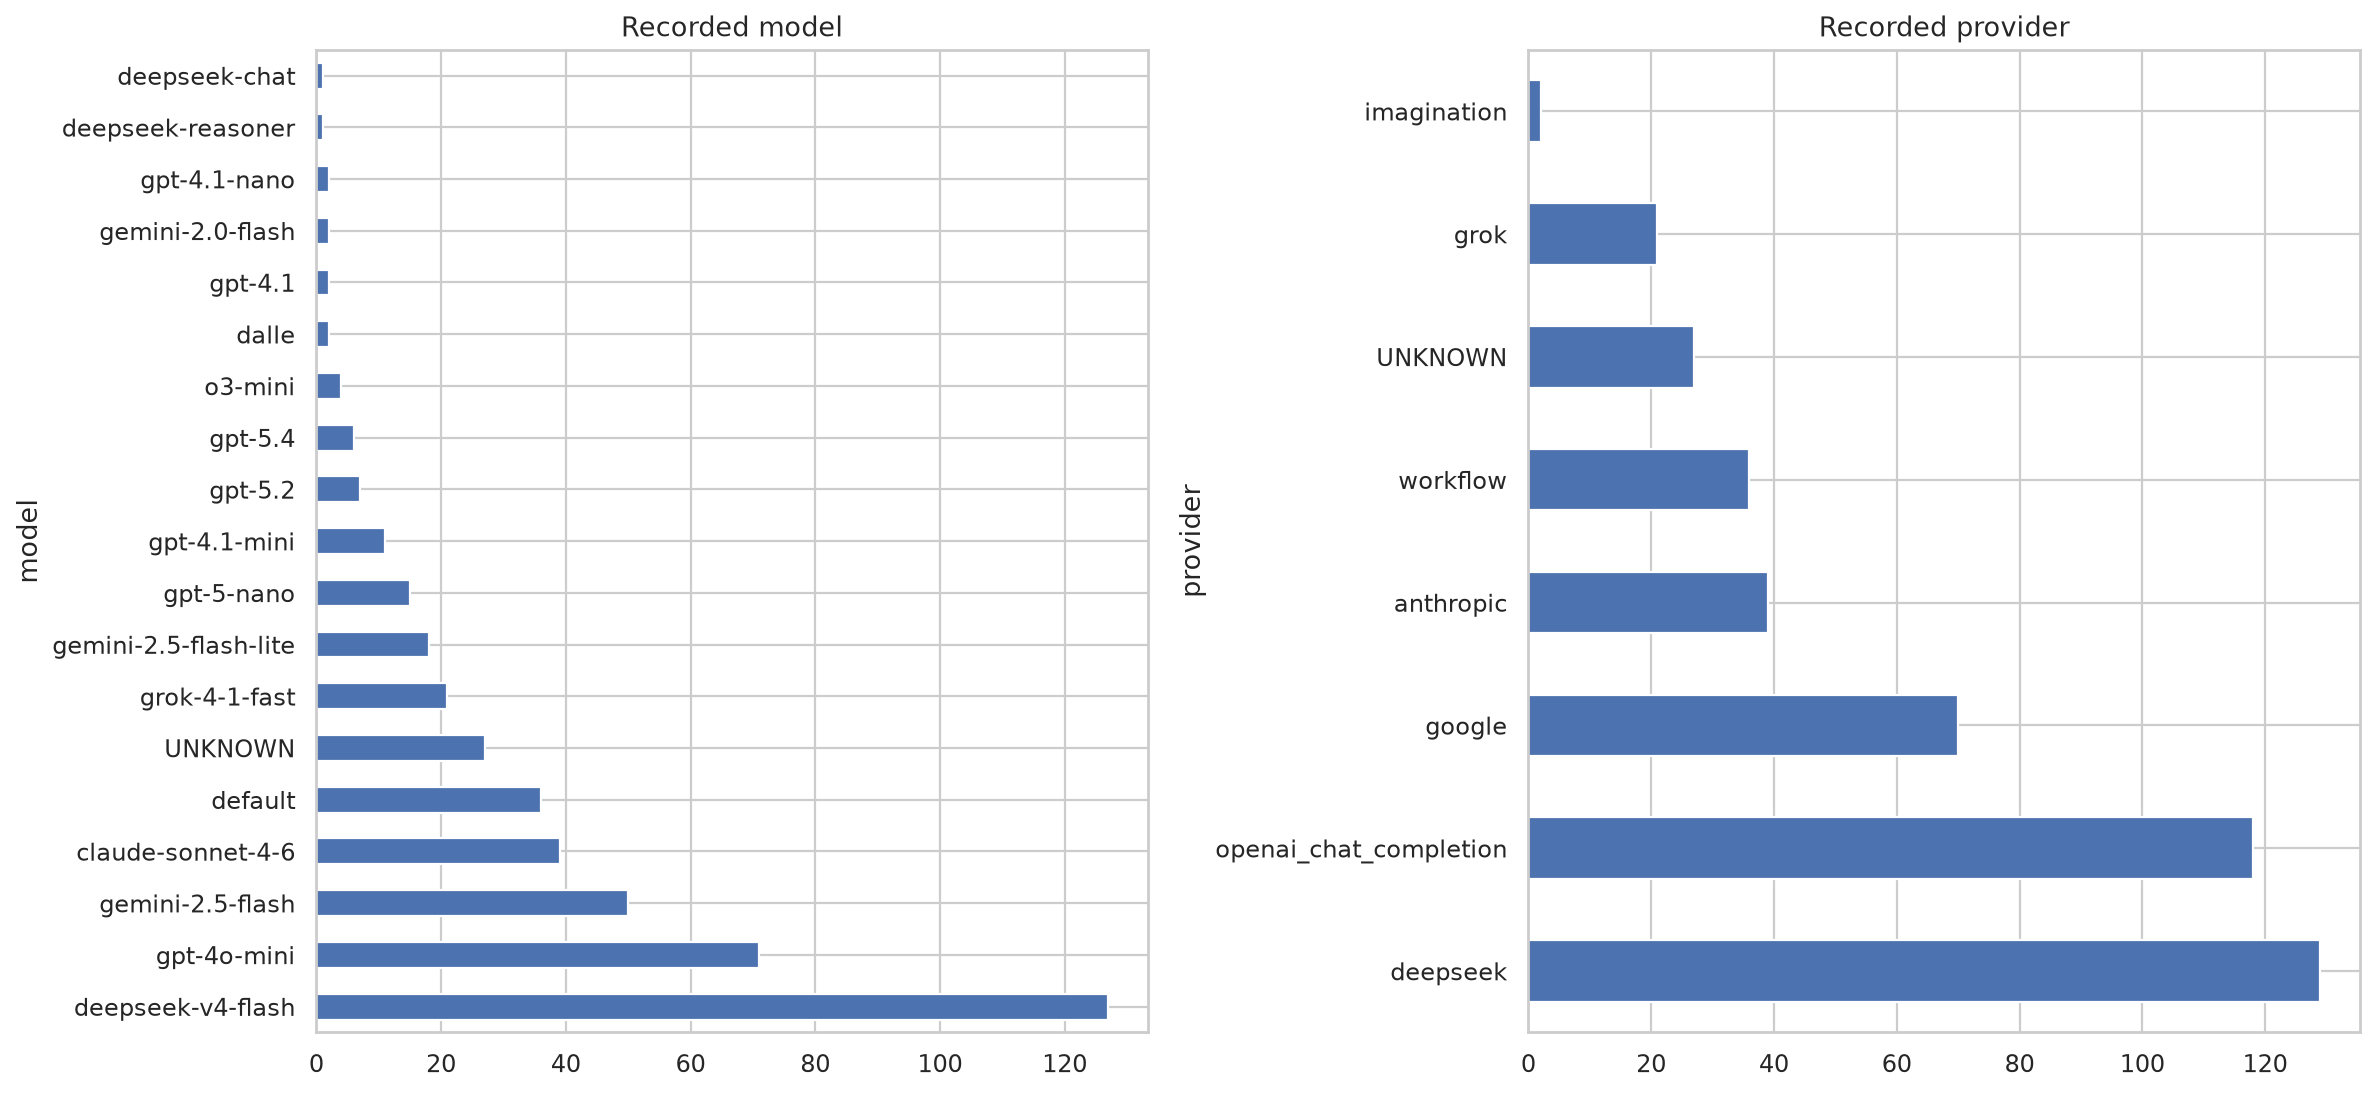

### 04_model_provider
ماتریس برای تعریف registry و رفع مدل‌های null/default مفید است؛ ناسازگاری نیازمند registry رسمی است.

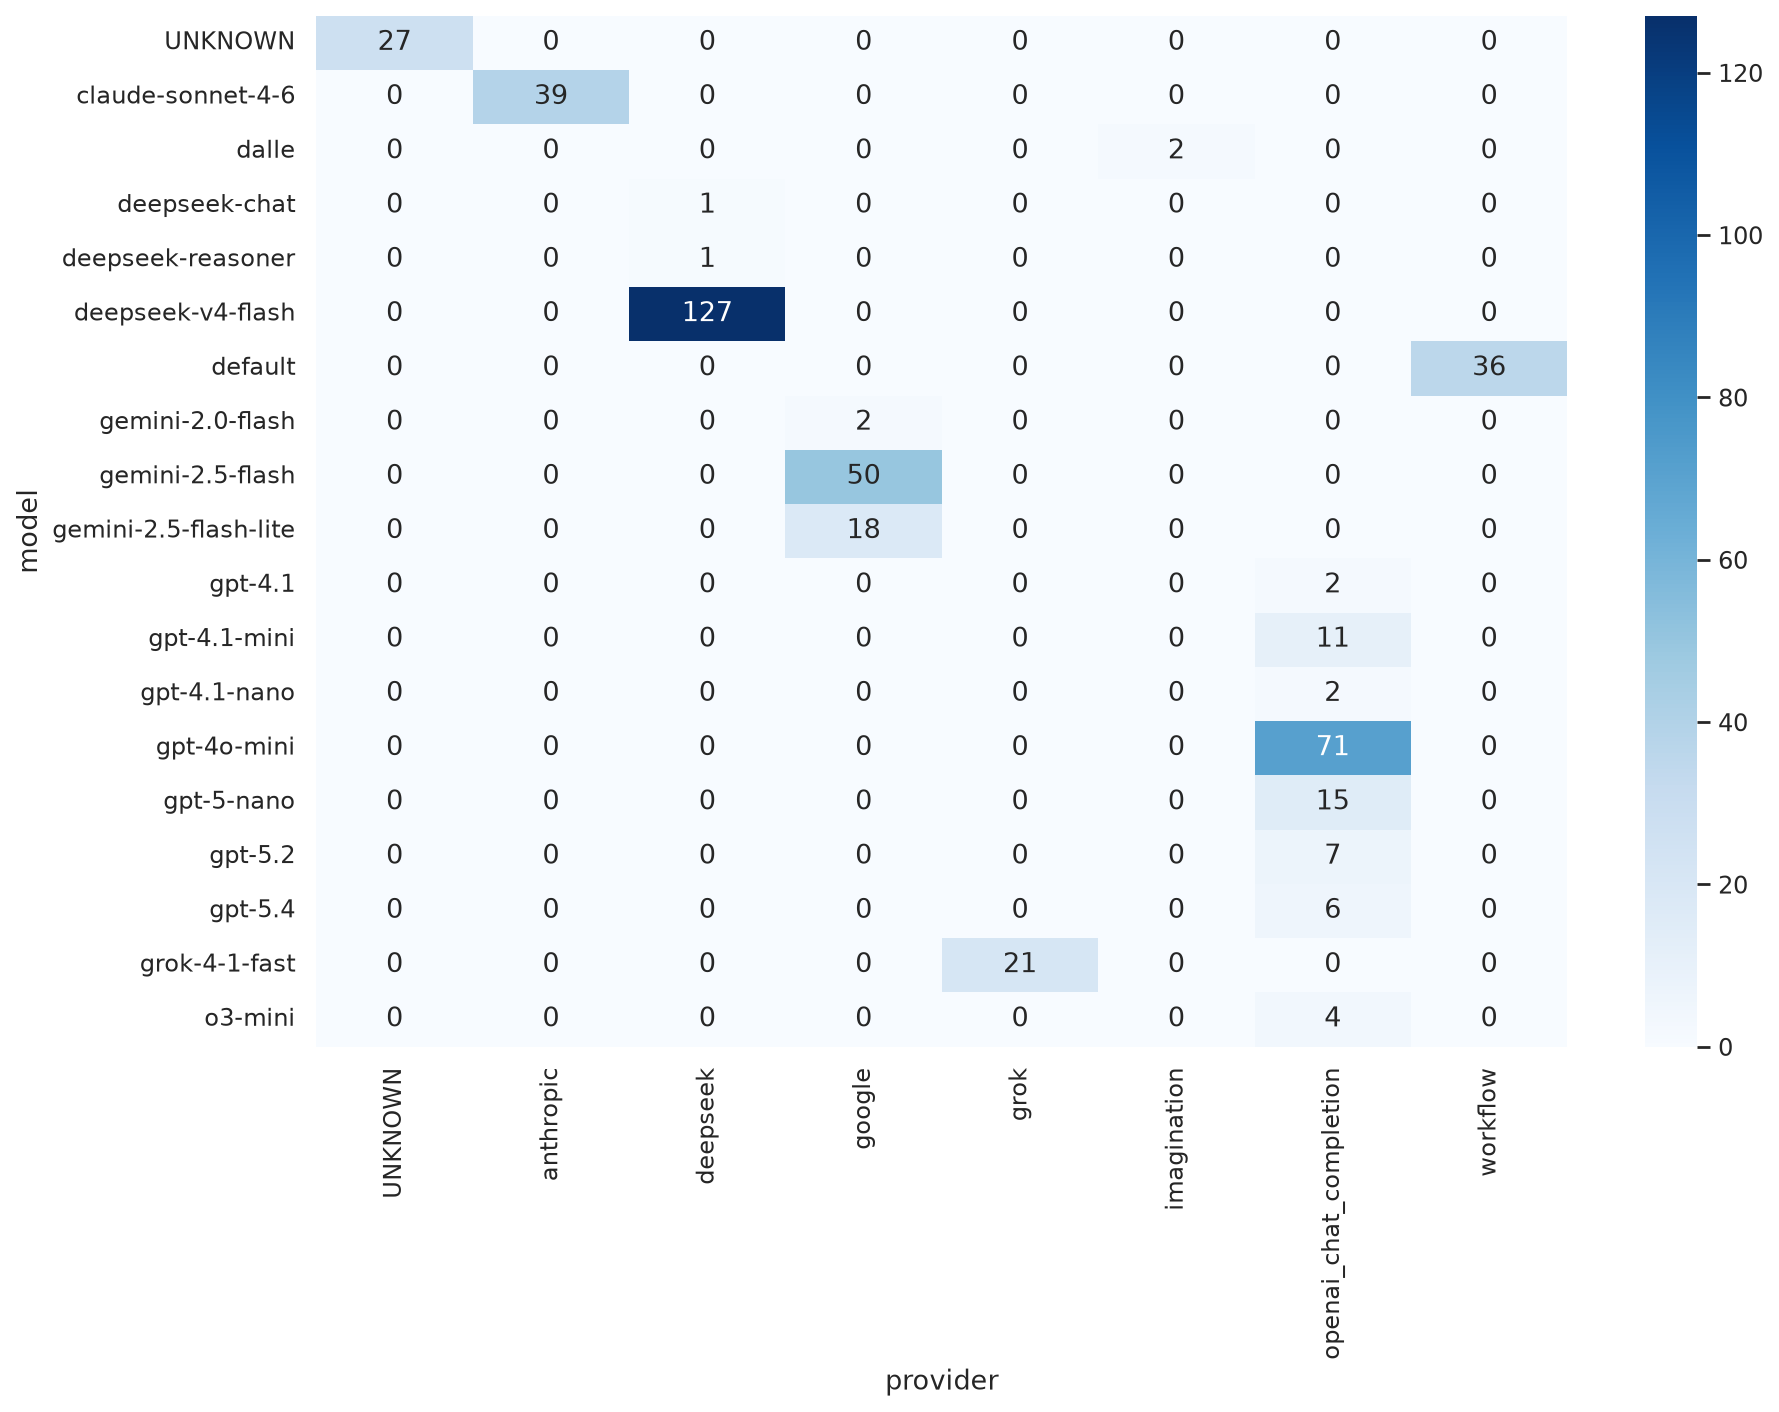

### 05_time
این نمودار زمان ثبت نمونه را توصیف می‌کند؛ timezone نامشخص مانع نتیجه‌گیری درباره ساعت اوج محلی تولید است.

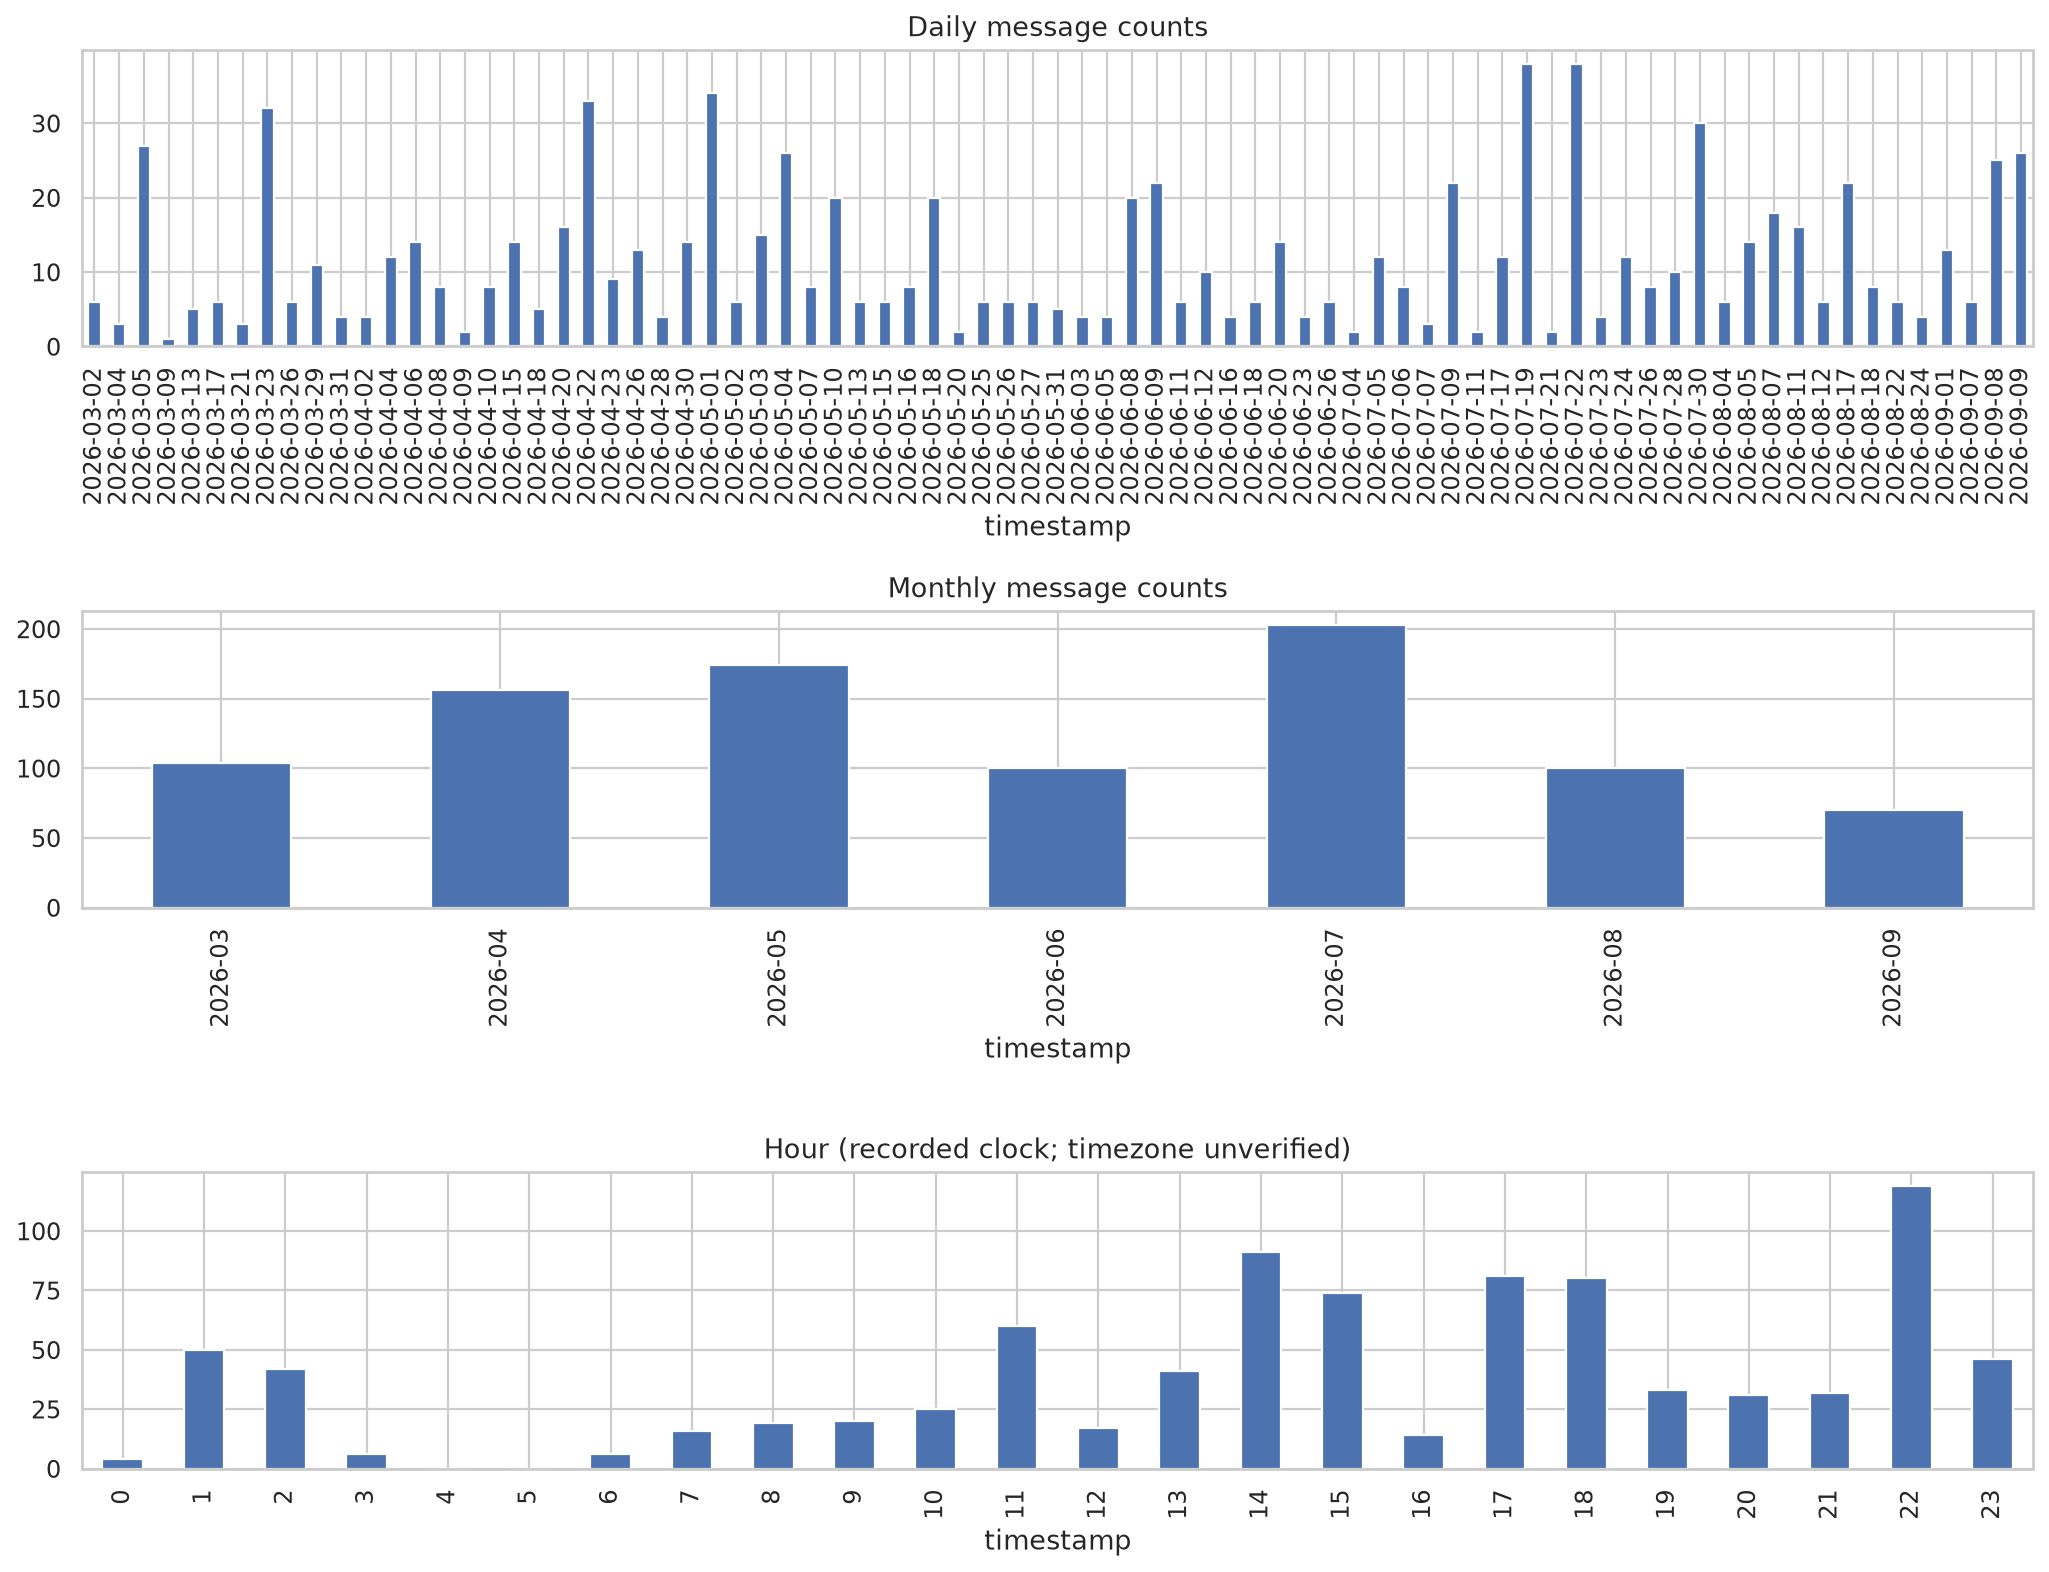

### 06_capabilities
حضور فیلد با دسترس‌پذیری آن پیش از routing یکسان نیست؛ RAG ثبت‌شده روی bot نیازمند retrieval-first است.

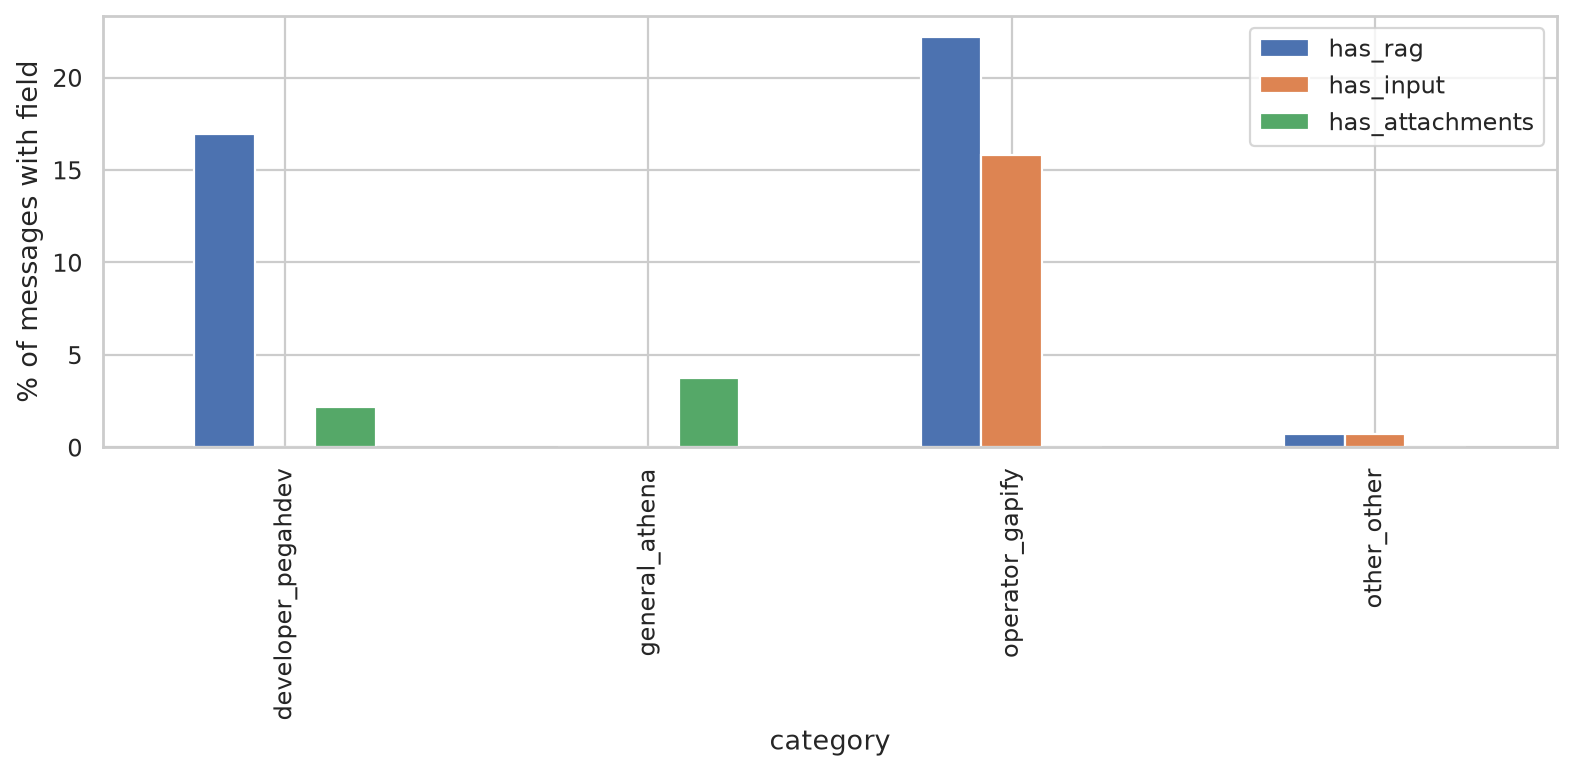

### 07_routing_features
ویژگی‌ها کم‌هزینه‌اند؛ uncertain باید مسیر بازبینی/مدل پیش‌فرض داشته باشد و برچسب‌ها نیازمند ارزیابی انسانی‌اند.

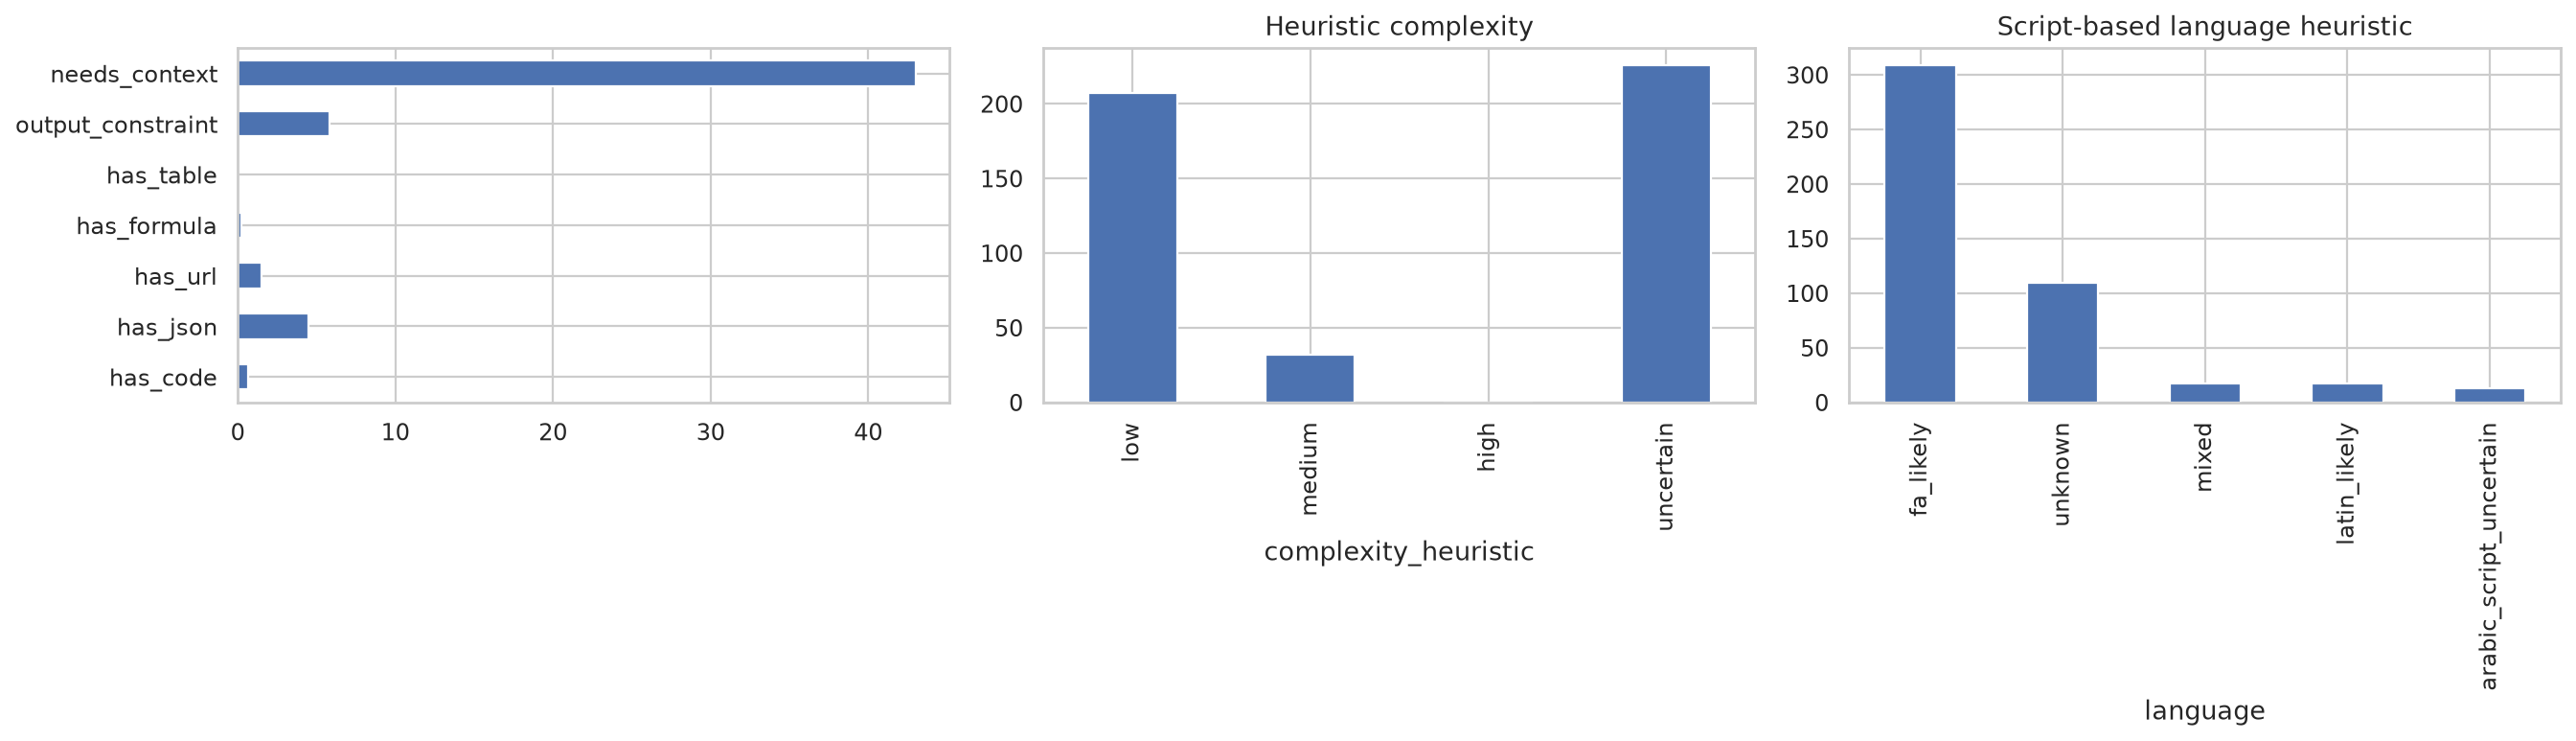

### 08_cache_threshold
اختلاف کش متن‌محور و کلید زمینه نشان می‌دهد شباهت واژگانی به‌تنهایی شاهد قابلیت reuse پاسخ نیست.

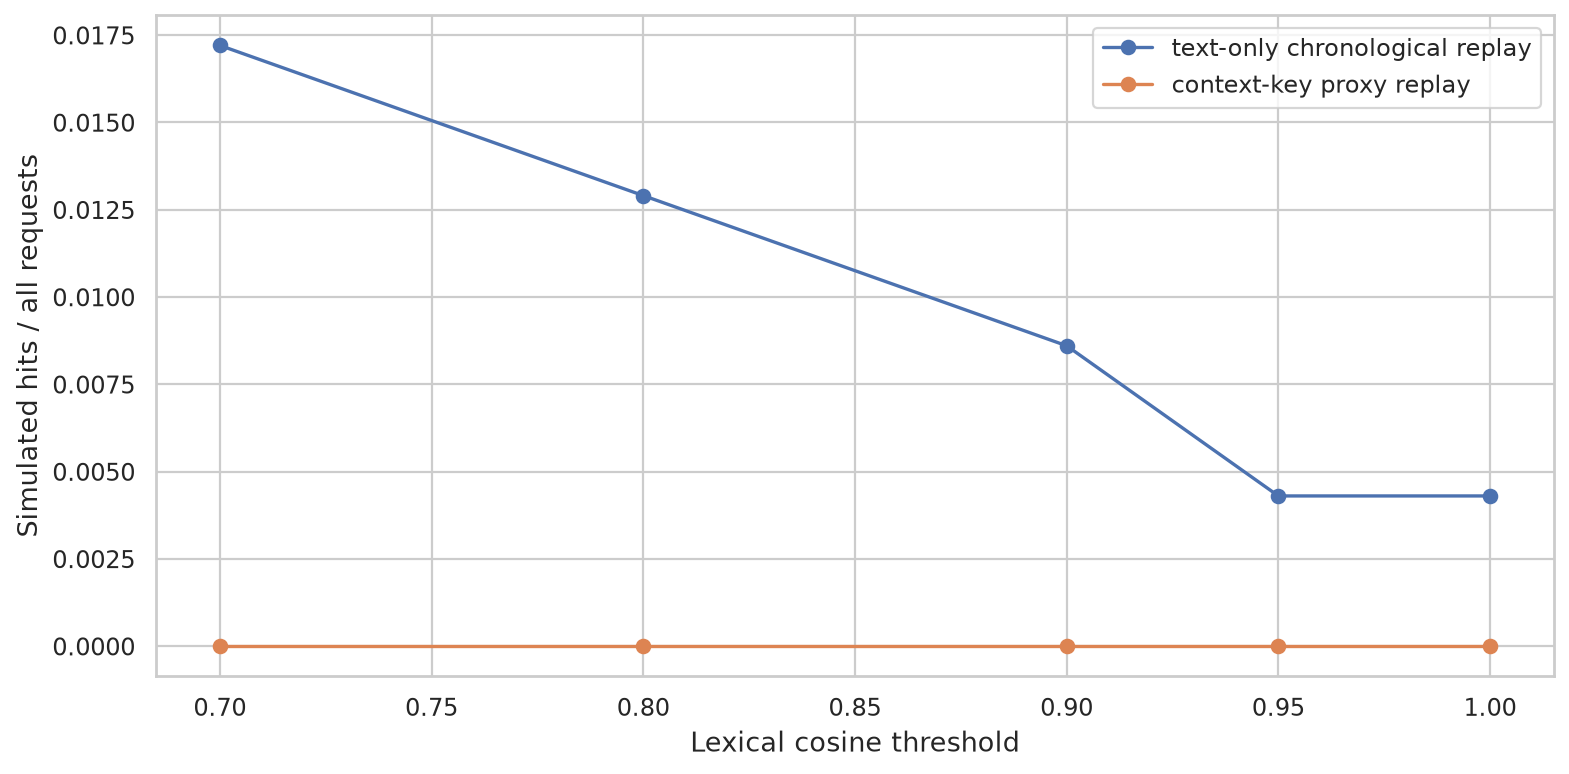

### 09_delay_proxy
اختلاف timestamp شامل ثبت لاگ و تأخیرهای نامعلوم است؛ برای SLA به span واقعی API و TTFT نیاز است.

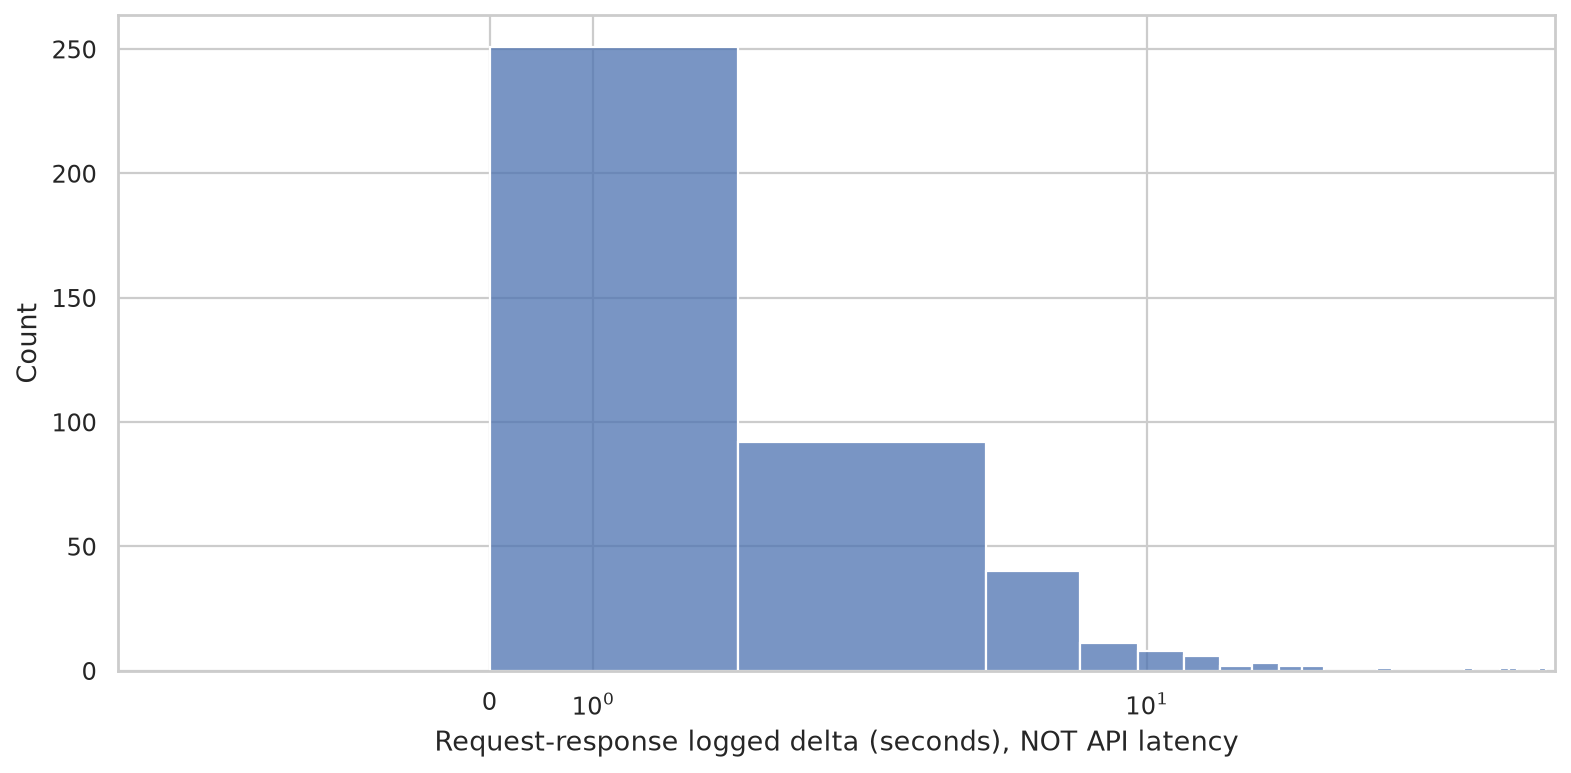

### 10_cost_scenarios
سناریوها صرفاً بودجه فرضی‌اند؛ بدون سنجش پاسخ مدل‌های جایگزین، حفظ کیفیت یا صرفه‌جویی قطعی اثبات نمی‌شود.

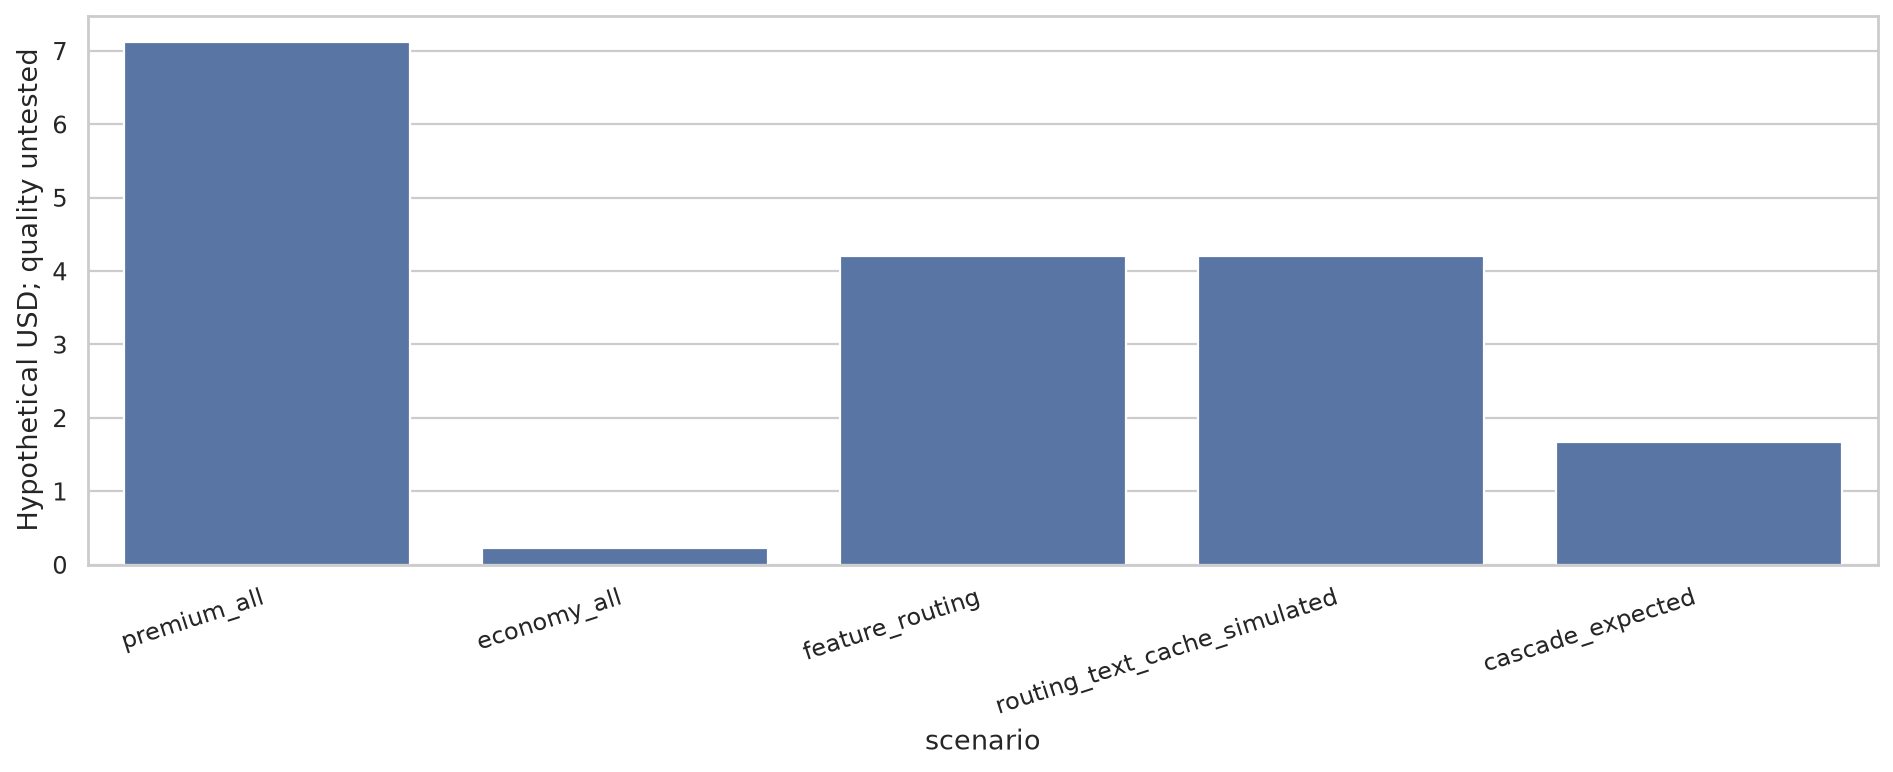

### 11_cost_sensitivity
بودجه cascade تابع نرخ escalation و hit فرضی است و هزینه تلاش اولیه و gate در تمام missها باقی می‌ماند.

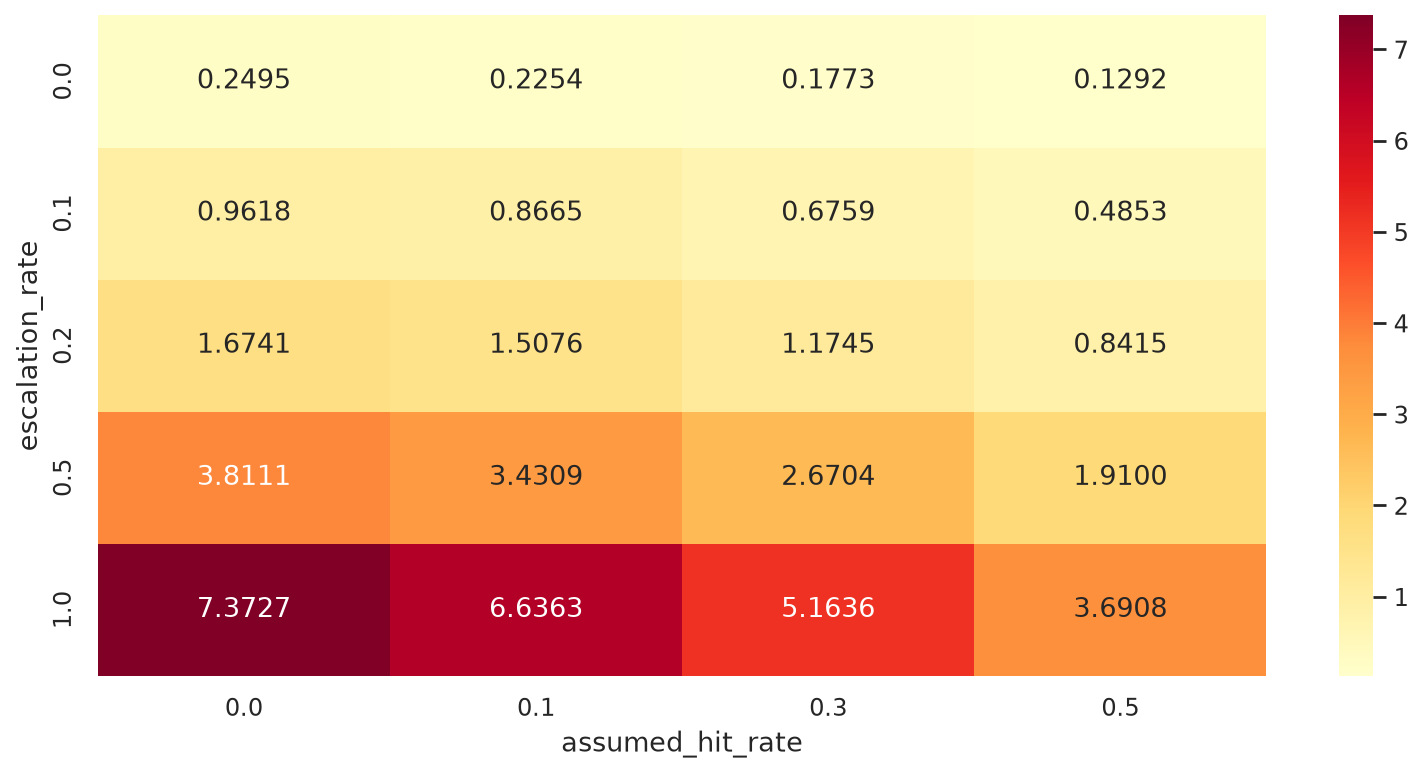

### 12_payload_components
instruction و RAG جدا از پاسخ تحلیل شده‌اند؛ payload واقعی و سیاست ارسال مجدد باید ثبت شوند.

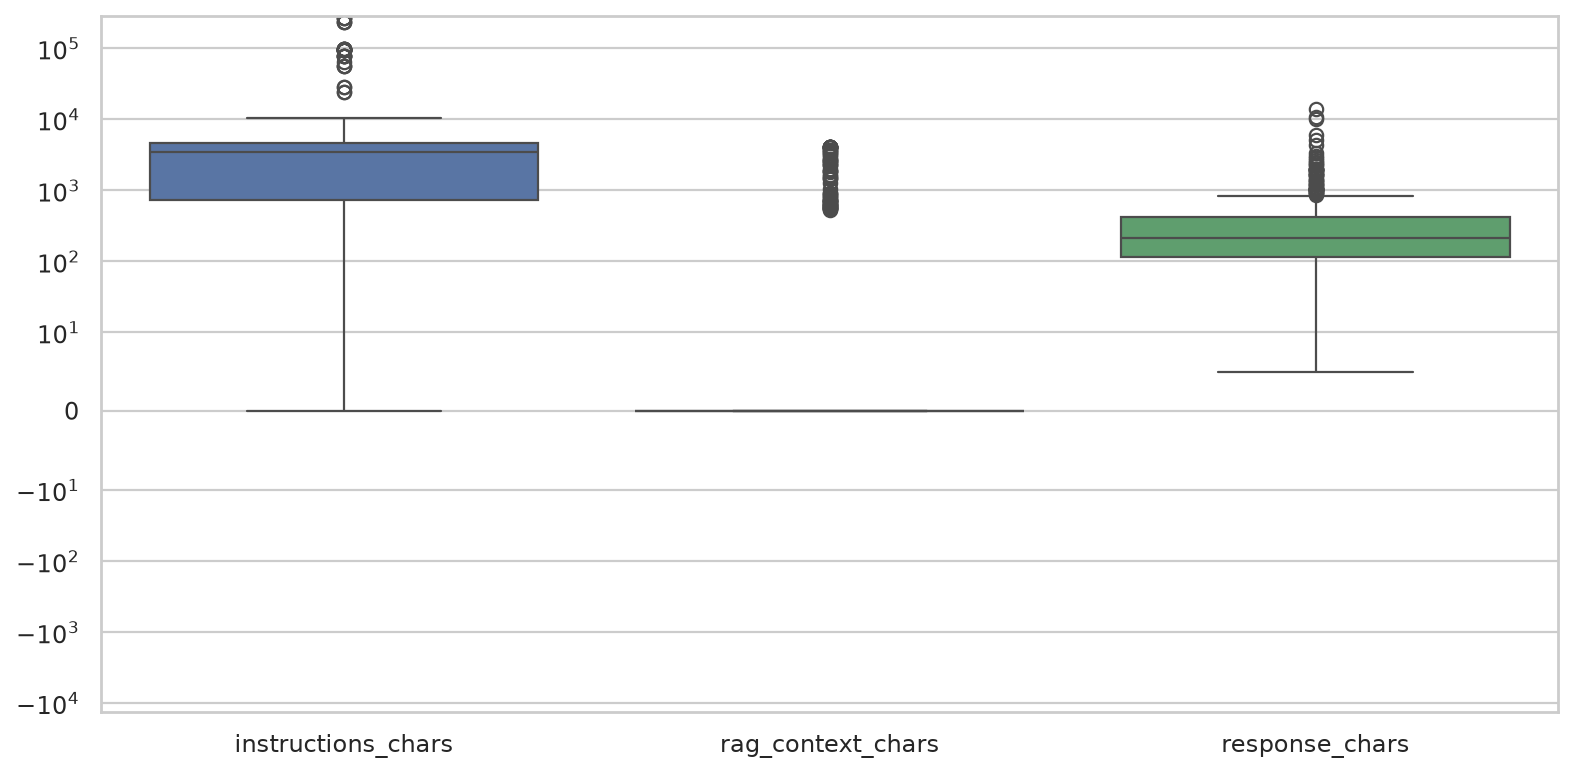

### 13_persian_render_check
نمایش فارسی با فونت DejaVu Sans و layout بومی Matplotlib≥3.11 بررسی شد؛ نسخه‌های قدیمی از reshaper/bidi استفاده می‌کنند تا دوبار وارونه‌سازی نشود. عنوان نمودارهای تحلیلی برای خوانایی فنی انگلیسی است.

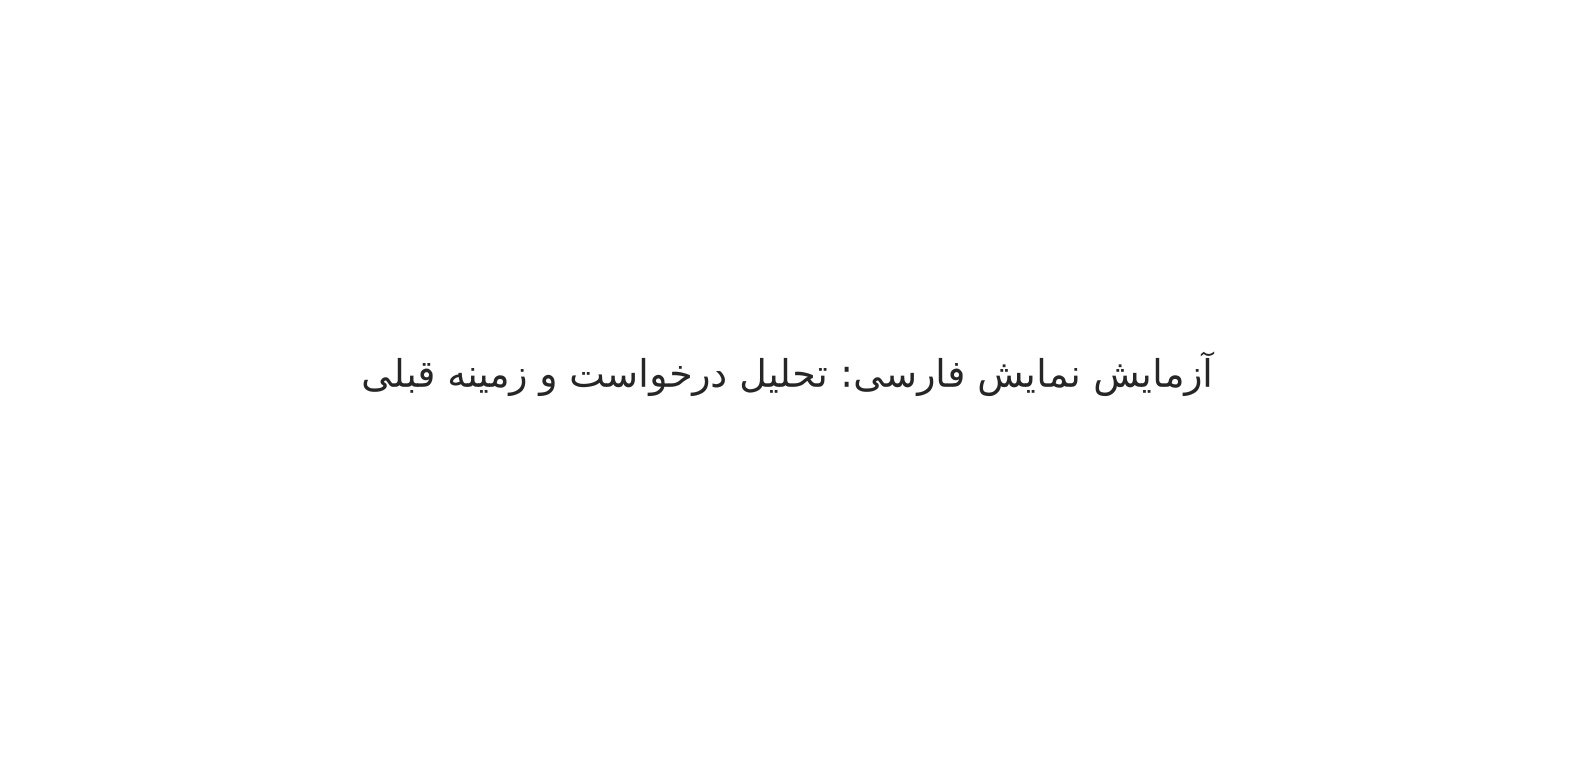

In [9]:
for name, interpretation in result['plots']:
    display(Markdown('### '+name+'\n'+interpretation))
    display(Image(filename=str(ROOT / 'reports/figures' / (name+'.png'))))

## ارزیابی آینده و گزارش نهایی
split پیشنهادی سطح نشست با اتصال تکرار دقیق غیرکوتاه ساخته شده؛ نزدیک‌تکرارها نیازمند ممیزی اضافی و split زمانی نیازمند purge overlap هستند. پاسخ تاریخی gold نیست؛ کیفیت، پیروی دستور، JSON/schema و حفظ زمینه باید مستقل با داور انسانی سنجیده شوند. embedding محلی و LLM-as-a-judge افزونه‌اند و پایه به آن‌ها وابسته نیست. گزارش کامل شامل محدودیت‌ها، داده‌های لازم، اولویت‌ها و جدول تصمیم است.

In [10]:
display(result['split'].groupby(['proposed_split','category']).size().to_frame('sessions'))
display(Markdown((ROOT / 'reports/eda_report.md').read_text(encoding='utf-8')))

sessions
proposed_split category                    
test           developer_pegahdev         2
               general_athena             6
               operator_gapify            7
               other_other                4
train          developer_pegahdev        20
               general_athena            11
               operator_gapify           13
               other_other               17
validation     developer_pegahdev         3
               general_athena             8
               operator_gapify            5
               other_other                4

# گزارش EDA پروژه Metis-Auto

**نوع تحلیل:** مشاهده محلی، heuristic قابل‌ممیزی و شبیه‌سازی با فرضیات؛ seed=20261006.

## ۱. خلاصه مدیریتی
داده شامل **100 نشست، 907 پیام، 465 پیام user و 442 پیام bot** است. درخواست بی‌پاسخ: 19/465 (4.09٪). نشست دقیقاً یک user و یک bot: 0/100 (0.00٪). مدل غیر-null: 18؛ provider غیر-null: 7. تکرار مازاد درخواست خام: 55/465 (11.83٪)؛ نرمال‌شده: 55/465 (11.83٪). replay متن‌محور در آستانه ۰٫۹: 4/465 (0.86٪)؛ proxy کلید زمینه: 0/465. این توازن نمونه، سهم واقعی ترافیک تولید را تعیین نمی‌کند. هیچ مدل جایگزین اجرا و هیچ صحت پاسخ کش ارزیابی نشده است.

## ۲. سند، ساختار و کیفیت داده
| metric | document | observed | agrees |
| --- | --- | --- | --- |
| sessions | 100 | 100 | true |
| messages | 907 | 907 | true |
| models_non_null | 18 | 18 | true |
| providers_non_null | 7 | 7 | true |
| rag_messages | 71 | 71 | true |
| input_messages | 29 | 29 | true |
| attachment_messages | 14 | 14 | true |

| category | sessions | messages | users | bots | session_share_percent | message_share_percent |
| --- | --- | --- | --- | --- | --- | --- |
| developer_pegahdev | 25 | 183 | 95 | 88 | 25.0 | 20.1764 |
| general_athena | 25 | 266 | 139 | 127 | 25.0 | 29.3275 |
| operator_gapify | 25 | 171 | 86 | 85 | 25.0 | 18.8534 |
| other_other | 25 | 287 | 145 | 142 | 25.0 | 31.6428 |


بازه پیام‌ها: **2026-03-02 19:31:47+00:00 تا 2026-09-09 15:56:39+00:00** (UTC در parser صرفاً برچسب محاسباتی برای زمان بدون timezone است). بازه created_at: 2026-01-14 19:30:34+00:00 تا 2026-09-09 15:48:17+00:00. سند January–September 2026 را ذکر می‌کند؛ این نمونه پیام ثبت‌شده ژانویه/فوریه ندارد، اما بازه created_at با سند سازگار است. بنابراین اختلاف تعریف بازه پیام و ایجاد نشست باید روشن شود. تعداد مدل‌ها null را حذف و default را یک مقدار مشاهده‌شده می‌شمارد؛ default/workflow را مدل واقعی فرض نمی‌کنیم. نام مدل در سند مثال تاریخی است، نه الزام انتخاب.

### روش واحد تحلیل و جفت‌سازی
شناسه session_key از موقعیت گروه/نشست ساخته شده تا شناسه تکراری باعث ادغام نشود. ترتیب آرایه حفظ می‌شود؛ timestamp ترتیب مکالمه را بازنویسی نمی‌کند. هر user یک ردیف دارد. بلوک user متوالی به بلوک bot بلافاصله بعد متصل می‌شود؛ چند user یا چند bot وضعیت ambiguous_block دارند. متن تمام پاسخ‌های بلوک و اندیس‌ها حفظ می‌شوند؛ این اتصال ادعای پاسخ مستقل برای هر درخواست نیست. user بدون بلوک پاسخ با unanswered باقی می‌ماند. bot ابتدایی در issues با orphan_response ثبت می‌شود. تاریخچه فقط شامل پیام‌های پیش از خود درخواست است. هزینه و proxy اصلی فقط از paired غیرمبهم محاسبه می‌شوند.

### یافته‌های کنترل کیفیت با مخرج
| scope | issue | field | count | denominator | percent | example |
| --- | --- | --- | --- | --- | --- | --- |
| message | before_session_created | timestamp | 2 | 907 | 0.2205 | 2026-04-15T06:25:54 |
| message | consecutive_role | role | 19 | 907 | 2.0948 | user |
| message | duplicate_message_content | content | 75 | 907 | 8.269 | مشکل یا سوالتون رو مطرح کنید تا بتونم راهنماییتون کنم. |
| message | empty_string | instructions | 7 | 442 | 1.5837 |  |
| message | invalid_json_like | content | 8 | 907 | 0.882 | {"size":76,"new_price":[NATIONAL_ID],"has_loan":false,"cabinet_material":[],"occupancy_status":"تخلیه","elevator":"true","price":{"mode":"مق |
| message | mixed_text_json | content | 32 | 907 | 3.5281 | {"ownership_transfer":"بله","successfully_inspected_by_ai":false,"price":{"mode":"مقطوع","value":225000000},"camera_status":"ok","status":"l |
| message | null | instructions | 27 | 442 | 6.1086 |  |
| message | null | model | 27 | 442 | 6.1086 |  |
| message | null | provider | 27 | 442 | 6.1086 |  |
| message | orphan_response | role | 6 | 907 | 0.6615 | Error |
| request | unanswered_request | role | 19 | 465 | 4.086 | تخلف یک راننده رو می خواستم گزارش بدهم |

### کنترل‌های صفر و وضعیت ساختار
| check | occurrences |
| --- | --- |
| missing | 0 |
| invalid_type | 0 |
| invalid_structure | 0 |
| duplicate_id_within_group | 0 |
| duplicate_id_across_groups | 0 |
| duplicate_session_exact | 0 |
| duplicate_session_content | 0 |
| count_mismatch | 0 |
| unexpected_role | 0 |
| invalid_timestamp | 0 |
| nonmonotonic_timestamp | 0 |
| before_session_created | 2 |
| orphan_response | 6 |
| unanswered_request | 19 |
| consecutive_role | 19 |

### timezone و انواع content
| role | timezone | count |
| --- | --- | --- |
| bot | unknown | 442 |
| user | unknown | 465 |

| role | content_kind | count |
| --- | --- | --- |
| bot | invalid_json_like | 2 |
| bot | mixed_text_json | 19 |
| bot | plain_text | 396 |
| bot | valid_json | 25 |
| user | invalid_json_like | 6 |
| user | mixed_text_json | 13 |
| user | plain_text | 444 |
| user | valid_json | 2 |

از 8 content شروع‌شونده با JSON نامعتبر، 2 مورد صرفاً با quote آزمایشی placeholderهای بدون quote به JSON کامل قابل parse تبدیل می‌شوند و 2 مورد دیگر prefix قابل parse همراه متن باقی‌مانده دارند. این تشخیص جانشین ترمیم داده نیست؛ فایل و متن خام تغییر نکرده‌اند. invalid_json_like می‌تواند متن ترکیبی با prefix معیوب نیز باشد؛ معیار صرفاً نحوی است. احتمال اثر ناشناس‌سازی بر اعتبار JSON باید هنگام ارزیابی schema جدا شود.

### تنوع فیلدهای اختیاری
| rag_shape | count |
| --- | --- |
| {"context": {"list_item_shapes": ["\"str\""]}, "query": "str"} | 71 |

| input_shape | count |
| --- | --- |
| {"items": {"list_item_shapes": ["{\"choices\": {\"list_item_shapes\": [\"\\\"str\\\"\"]}, \"default\": \"NoneType\", \"label\": \"str\", \"name\": \"str\", \"placeholder\": \"NoneType\", \"required\": \"bool\", \"type\": | 29 |

| attachments_shape | count |
| --- | --- |
| {"list_item_shapes": ["{\"content\": \"str\", \"contentType\": \"str\"}"]} | 14 |

| role | has_rag | has_input | has_attachments | role_messages |
| --- | --- | --- | --- | --- |
| bot | 71 | 29 | 0 | 442 |
| user | 0 | 0 | 14 | 465 |
**نکته زمان دسترسی:** تمام inputهای این نمونه روی bot هستند: widget خروجی‌اند، نه ورودی ساختاریافته اثبات‌شده روی درخواست جاری. RAG نیز فقط روی bot ثبت شده است. همه پیوست‌ها روی user هستند. widget قبلیِ قابل مشاهده، نشانه context در heuristic است؛ مقدار انتخاب‌شده ساختاریافته مستقلی ثبت نشده.

| contentType | attachments_count |
| --- | --- |
| IMAGE | 15 |
مخرج نرخ حضور پیوست تعداد پیام است؛ تعداد فایل‌ها جداست. contentType مقدار IMAGE است نه MIME رسمی؛ محتوای تصویر دانلود یا ارزیابی نشده.

### ممیزی فیلدهای تو در تو
| path | parent_objects | present | absent | null | empty_string | empty_container |
| --- | --- | --- | --- | --- | --- | --- |
| root[].sessions[].messages[].instructions | 907 | 442 | 465 | 27 | 7 | 0 |
| root[].sessions[].messages[].model | 907 | 442 | 465 | 27 | 0 | 0 |
| root[].sessions[].messages[].provider | 907 | 442 | 465 | 27 | 0 | 0 |
| root[].sessions[].messages[].input.items[].default | 29 | 29 | 0 | 29 | 0 | 0 |
| root[].sessions[].messages[].input.items[].label | 29 | 29 | 0 | 0 | 16 | 0 |
| root[].sessions[].messages[].input.items[].name | 29 | 29 | 0 | 0 | 20 | 0 |
| root[].sessions[].messages[].input.items[].placeholder | 29 | 29 | 0 | 29 | 0 | 0 |
ممیزی تمام مسیرها در field_completeness.csv است؛ غیبت optionalها مجاز و غیبت model روی user متناسب نقش است. null پیش‌فرض/placeholder widget الزاماً خطای داده نیست. issueها روی فیلدهای الزامی و اختلال ساختار تمرکز دارند؛ در جدول بالا مخرج parent_objects همان container مربوط است.

### ناشناس‌سازی
| placeholder | occurrences |
| --- | --- |
| [NAME] | 3 |
| [NATIONAL_ID] | 8 |
| [COORD] | 4 |
| [LANDLINE] | 4 |
| [ENROLLMENT] | 1 |
| [ALLOCATION] | 1 |
| [ANALYSIS] | 2 |
| [PHONE] | 3 |
placeholder مفقودی نیست. جایگزینی نام/شناسه می‌تواند افراد مختلف را یکسان کند و کش را بیش‌برآورد کند؛ حذف اعداد و شناسه‌ها می‌تواند تشخیص پیچیدگی محاسباتی و وابستگی به وضعیت فرد را مخدوش کند. ادعای حذف PII در سند جایگزین بررسی یا شناسه tenant نیست.

## ۳. توصیف طول، کاربرد و مدل
| unit | group | grouping | metric | n | mean | median | p90 | p95 | min | max | iqr_outliers |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| session | all | all | actual_message_count | 100 | 9.07 | 6.0 | 20.0 | 25.15 | 3 | 44 | 7 |
| session | all | all | actual_user_turns | 100 | 4.65 | 3.0 | 10.0 | 14.0 | 2 | 23 | 6 |
| session | all | all | actual_bot_turns | 100 | 4.42 | 3.0 | 10.0 | 12.1 | 1 | 21 | 5 |
| message | all | all | chars | 907 | 312.2304 | 86.0 | 704.4 | 1349.0 | 2 | 13795 | 108 |
| message | all | all | words | 907 | 52.6009 | 17.0 | 117.2 | 216.4 | 1 | 1638 | 101 |
| bot | all | all | instructions_chars | 442 | 10889.9276 | 3486.0 | 8133.0 | 79050.0 | 0 | 271155 | 33 |
| rag_message | all | all | rag_context_chars | 71 | 1872.8732 | 1476.0 | 4019.0 | 4019.0 | 526 | 4019 | 0 |
| message | bot | role | chars | 442 | 491.5633 | 210.0 | 1025.2 | 1765.95 | 5 | 13795 | 55 |
| message | bot | role | words | 442 | 85.2172 | 40.0 | 174.9 | 327.65 | 1 | 1638 | 47 |
| message | user | role | chars | 465 | 141.7677 | 29.0 | 181.6 | 424.0 | 2 | 4666 | 54 |
| message | user | role | words | 465 | 21.5978 | 6.0 | 36.2 | 60.2 | 1 | 851 | 55 |
| bot | bot | role | instructions_chars | 442 | 10889.9276 | 3486.0 | 8133.0 | 79050.0 | 0 | 271155 | 33 |
| rag_message | bot | role | rag_context_chars | 71 | 1872.8732 | 1476.0 | 4019.0 | 4019.0 | 526 | 4019 | 0 |
| request_historical_response_group | all | all | request_chars | 465 | 141.7677 | 29.0 | 181.6 | 424.0 | 2 | 4666 | 54 |
| request_historical_response_group | all | all | request_words | 465 | 21.5978 | 6.0 | 36.2 | 60.2 | 1 | 851 | 55 |
| request_historical_response_group | all | all | history_chars | 465 | 1869.3441 | 521.0 | 4851.6 | 8653.4 | 0 | 34886 | 55 |
تمام طول‌ها کاراکتر یا کلمه whitespace هستند؛ هیچ‌کدام تعداد توکن واقعی نیستند. IQR فقط پرچم توصیفی است؛ نقاط پرت حذف نشده‌اند. آمار تفکیکی کامل category/model/provider در descriptive_statistics.csv است.

### مدل–provider ثبت‌شده
| model | provider | bot_messages |
| --- | --- | --- |
| claude-sonnet-4-6 | anthropic | 39 |
| dalle | imagination | 2 |
| deepseek-chat | deepseek | 1 |
| deepseek-reasoner | deepseek | 1 |
| deepseek-v4-flash | deepseek | 127 |
| default | workflow | 36 |
| gemini-2.0-flash | google | 2 |
| gemini-2.5-flash | google | 50 |
| gemini-2.5-flash-lite | google | 18 |
| gpt-4.1 | openai_chat_completion | 2 |
| gpt-4.1-mini | openai_chat_completion | 11 |
| gpt-4.1-nano | openai_chat_completion | 2 |
| gpt-4o-mini | openai_chat_completion | 71 |
| gpt-5-nano | openai_chat_completion | 15 |
| gpt-5.2 | openai_chat_completion | 7 |
| gpt-5.4 | openai_chat_completion | 6 |
| grok-4-1-fast | grok | 21 |
| o3-mini | openai_chat_completion | 4 |
| NaN | NaN | 27 |
تغییر مدل در 0/100 (0.00٪) نشست و provider در 0/100 (0.00٪) نشست دیده می‌شود. تغییر نام ثبت‌شده اثبات cascade/failover نیست؛ reason و attempt_id موجود نیست. instruction غیرخالی 408/442 (92.31٪) پیام bot و 78 نسخه hash دارد؛ در 0/100 (0.00٪) نشست متن instruction تغییر می‌کند. hash متن خام نسخه رسمی policy نیست؛ متن می‌تواند اطلاعات پویا داشته باشد. در absence registry، مدل–provider چندگانه صرفاً پرچم بازبینی است و ناسازگاری قطعی نیست.

تعداد مدل‌های ثبت‌شده با بیش از یک provider غیر-null: 0. default/workflow: 36/442 (8.14٪)؛ dalle/imagination: 2/442 (0.45٪). متن bot دقیقاً برابر Error: 2/442 (0.45٪)؛ این نشانه متنی دلیل کافی برای نوع خطای API یا نرخ failover نیست.

### تنوع instruction
| instructions_hash | bot_messages | chars |
| --- | --- | --- |
|  | 34 | 0 |
| 040a2c3feb98478bd4a88da64cefa53f13dfca386625b703a12a003ab117ea56 | 18 | 4696 |
| 0451ae30a7d6a63df428eccd110ba8c18ec3eec119079a3b31ac963c7906c0fa | 10 | 3560 |
| 0947f9a77b19fd024f36449e78db2a07cb666c13e09276dc7cd87c298e34fc16 | 5 | 425 |
| 0e928a6552deead1749377fdac932042f37be03f5145c5573c27f2c0f479c8a9 | 5 | 3949 |
| 0ffe84bf54917544c3c6be5d462e8f3e52fe3ee844288acb3db628f8777a8a61 | 6 | 100 |
| 108979641a97c6171793ebdde5e4f3b6bd3208f6e409b1dc1fbc08dc9743317a | 5 | 3387 |
| 132870532e64e5aa9173754eac66d7c7675a1b5c276608b3a5ddfd2ae22f94c5 | 12 | 3793 |
| 19d1441df8403d7d50a1a0aa263bbf992cfbb71857da0255407dafb735a4eb9e | 2 | 3352 |
| 1a61d12357bda2a4a69521d14cdc70743dcac683b7546eef532027ec1237c3e3 | 2 | 1815 |
| 1aec64cc9fd7e8c6951d199b0a2eb19a083537259f04a454922fd35552a44669 | 14 | 3361 |
| 1b1c2f5f6e9ffdfb3d260f56639dba7fc253d2f3fa56c90cc079e27225967bd5 | 3 | 293 |
| 1c4b28188b3904fb17ea64989cd3f2789413fe6a7600a63d7e26d9102874a136 | 2 | 3811 |
| 1fc0ff6893ae09745fe6f64390ebb8b380cc92b3a2d3d5cc612982cb743890ce | 3 | 7037 |
| 23b4d6da417e7c190f130abedde84717330b8750361624bae50e5ab8ba3b257a | 3 | 271155 |
| 2d4bd222eacb674affc6545ba96ad83a898ffcf7bd80d3fd09a10b50b1d49414 | 6 | 3727 |
| 31effab2dd52ffb6251ac94d91e61229b0743ec27bdaad4a6e12be0fb63b501c | 2 | 28182 |
| 325d41b082699f3c9c1fb0634929f8c280a8960559f80e24e9c6338a6b7c8dd2 | 15 | 733 |
| 348f2787521539c8d8a6916d208907e92c1849ba10c3be086d74c02f98c77162 | 2 | 3178 |
| 3d78860acd032034e8c62e2f9b94925897e497765e5990fa8416be9eb116c637 | 4 | 4642 |
| 4377c0bd3d736e6cd54a572500c1423eed41e45eeafdd83022c3eec92932f153 | 3 | 233058 |
| 43a9622bc97d85b6104bc2865c43b13bbddfaee8e4890dc4b1608fb2625a18f2 | 1 | 64817 |
| 46f879599fa5307279433905ad5bc30984774bb234690a558389b0a47b113a87 | 2 | 3634 |
| 481c836b72ade73cbf6410162fe3e53ab605ecdcf1a32baa6903265259d6e2cb | 7 | 3169 |
| 49bb6893924d32ececd076e943202081372f187c5679bcff32f5220b6b5699a6 | 4 | 1436 |
| 5001cdac94691b8ebd21cd032a332467d3bc248f502d6b2ea9c385f09ae11eb0 | 2 | 2517 |
| 50d5ec9ddb6bfc21d16277ffa679992df2e396adf68ca65e2660ad16223c6ebb | 4 | 3447 |
| 5b0a50a6e3a6509413574051109833bb5da48608f63809277d77f31d913acb77 | 5 | 79050 |
| 5bd7c63fe8adfe1de57c634dcdb768ee44a42e32be8f4951b45b65c8b52bd95f | 2 | 3655 |
| 5d4dcd5e485310534e4bd9c1ed9ea774467e64ea13b2599b7033d98b3159531e | 8 | 93998 |
| 613ca863b9500a6b49ec2286ab0eee7d1daf4c9fbb9c622d598103e00b0226f4 | 2 | 3194 |
| 61ce9d711ebf6e3ad82f358a21e7dede6fd3564a19d9e599275212bf316762e7 | 15 | 3578 |
| 633ebe60483f359f1e705a66d4049da7c43930a26f114465eec790789af58ca3 | 7 | 7151 |
| 71d74c97b9c6ae4aa3d858fc72d44aa901df12d32851fc824329539962a38c9f | 2 | 6109 |
| 733d21168deb8df95d6d96434661ce53d3f31c008d79a63a8ce93d9287c4eccb | 2 | 3486 |
| 750a8091fdb36bcd3d1a4d932c056ed5ce82f9f40f0b8c187442dabcc625eb0b | 2 | 53 |
| 7673720d6c897087c20cfc7b400cbf200436d228f50e95a16ab67eb0de636ea4 | 2 | 3396 |
| 7bbbf9ee347a275d1527731b72071e1d019d723694a4e026e6e6e3687324fcf8 | 3 | 7809 |
| 7f8afcccd73ecc6db1f6c7c003f3192ae997007879c6a0d7744141cbad7c11ac | 2 | 255 |
| 8456692c08944f39f5d2e61bf020545ee1310512196442c92f0a3f7c43cb4984 | 9 | 4956 |
| 849282daf44d588f4a572becc09d05243858887e79f703291854d0098c30fa7a | 2 | 3486 |
| 863b0715d5ab089d59cf95b03be3926f374805544adf7aae1fdb8b1b41b15e48 | 6 | 8133 |
| 86a65423dae3c8673aa7c5e7e5ae21484e2fd35dafec695f0d1d19c247bec7eb | 11 | 2459 |
| 886c9a17790e01a387e06fda3b7f212ae87dca248f1f6c2ebbe2662f0d211018 | 4 | 1831 |
| 8aea345d395c48cf8e819c7fee47650f2cabb5e339b6c900433f2a66aeaca2a0 | 10 | 4984 |
| 9327310259e7b1cf3e8235d3df7b161b2e82ec6f07108bea658ea72da6c7417b | 3 | 4393 |
| 933a4492f803a548797eab771e957f676365b290371f50231593bd6734c3d213 | 10 | 3706 |
| 94652a34d152988cc1b8a97eb4fcd7ddf4909b562e6360bda38ec2c9a74e98b2 | 4 | 4481 |
| 94cc09540efc220fe0b890d573328a49d7669c758a9658ae9763bac1552b0151 | 17 | 4856 |
| 972b9959b5385c1ea4e1b27372ec2c1def72db9b0f657960fe94ed91494ac3d5 | 2 | 2580 |
| 9989baf6bad82bc3d2811f7fee977c102ce4d75e64b6367acf0f87b302c07960 | 1 | 1706 |
| 9f9465a0426e20f2702410cdb7d4248e4f84c41e032a6d4b66452359cb412b08 | 3 | 55496 |
| a2a93526dba95c4aa207e84d7c815ad40aa8511e61acd9189f918528713cc693 | 3 | 2472 |
| a5b1c75209d2b3f6a3832218c55dba5e47271e1bbb717d72f866e9166a8f15c3 | 2 | 3409 |
| a5e8f0ed18743a5bd19e83d773b2f919d77593be736982c6e48d38e7bef8aec9 | 6 | 10412 |
| a83dc51f69ddf82eed317833a43a6ff58ae98d8c69fda4376fc25be9839f66e4 | 2 | 23851 |
| ac5c2d55a15f65b0a8e7944bc808a32ee7bff3573c1bc1a829271363c72e81c6 | 15 | 348 |
| b1cc8b89fae597bfe64e8da67a16f3fba26622d5f1dee1e44f614d83eec689df | 2 | 506 |
| bad869312bf98883b9fbdd345c738675a565264e4c5fe7b64e18394375ab6b42 | 1 | 3398 |
| bcff964506b97f3da7fd46d11ebde5c0a94534da82627cfc756e790897d1a9ec | 1 | 14 |
| be47e09c40c181045b58e30a0e27ec1d5b9549628fa7c971c975cc303e2f62dc | 3 | 4360 |
| be9e9e4e543305e7967d7e65ba7216ef7edd0679fd94e5fc74dd8765cbaf9d1d | 6 | 3458 |
| c481779fbbd11ecbb5db7092c1c245cb4b1015225318fbc7be1932aa9d1e7815 | 6 | 3888 |
| d3c6546842dadd488270452185f5b4651414b25ddbc817584e695746f8962f68 | 3 | 383 |
| d4fce8d7c3bfe44c97eba15c2cd137fdf9d5bdcf5725c79f9eb096e650d2c031 | 3 | 56 |
| d72d7dd10e4baaec251f9936fc5e78b721fe87e071537ff7a1b015ff1019f1dd | 14 | 201 |
| db3cd5354c93eabfcc3dde1bafe32f02ddb2c649532bee4c38286794c9bee4a0 | 6 | 98147 |
| df8b4afbadc0bd81a13cf33d745bd71ed347be4456cd47084cb752a829b04b52 | 8 | 3241 |
| e56e89a8005936f7f690770efb2c799f5631201639d22b4905be3d93f26ff4c3 | 4 | 3965 |
| e60b2bbf91482a148158798a382a22b65e767d2ed72223b2e3a12f18eaa33db6 | 5 | 533 |
| e652a01d09896d708b805c67678984df23b26c800cfccff245204ec74be7e457 | 3 | 2259 |
| e896f3c24e5a787b9fedaef856e619b64b0d1201d4ffa45a609cb2e64437f092 | 5 | 2475 |
| ea2017fc51959c88d3f58a23822226fb355fda852fc244f448a3d11bd5e8e6c6 | 10 | 5393 |
| eb96d0d3d0ec8db2ad6821a77ce64250f2c6505a7e830983ea012710aa3dde25 | 7 | 288 |
| ec0c8f613c3433c53958b336c43e5c6f10856be464ed9da265226e0d40fe5834 | 4 | 504 |
| f1cd468973cebc51415f69e9d7a1a8d933ec3438f75e9e7153e4904fa4022029 | 5 | 3756 |
| f472cb8c37bda10a2695c25694d09861d37785068357089bb1bd0751c3f65a0c | 3 | 2218 |
| fb4729d54a92a8878644b06eb4f8ac9ecf6c369ff4ff56225c88fcaa93d521d9 | 2 | 8550 |
| fd3a04541d20f8afaad26204bacfb700e57ff86b29e690eb974b331545f44f8a | 3 | 1173 |

### کاربرد گروه‌ها با شاهد متن
| category | example | heuristic_types |
| --- | --- | --- |
| developer_pegahdev | این اطلاعات سلامت من است: \n نام: [NAME]\nوضعیت تاهل: مجرد\nوضعیت تحصیل: دانشجو\nوضعیت پریود: منظم ¦ آخرین دوره قاعدگی کاربر: یک دوره 28 روز | general; support; specialist |
| general_athena | Teach me how to make a consort flow | general; content_generation; multimodal |
| operator_gapify | بازیابی سایت ورودبا امیل | general; support; multi_step |
| other_other | سلام | general; data_transform; multi_step |
نمونه developer شامل اطلاعات سلامت/قاعدگی است؛ بنابراین نام دسته نقش یا هویت فرد را ثابت نمی‌کند. نوع کاربرد را باید در سطح درخواست و همراه context برچسب زد.

### واژگان جداگانه
| corpus | term | documents | corpus_documents | occurrences |
| --- | --- | --- | --- | --- |
| user_content | سلام | 56 | 465 | 56 |
| user_content | رو | 51 | 465 | 65 |
| user_content | یه | 31 | 465 | 36 |
| user_content | های | 28 | 465 | 88 |
| user_content | کردم | 28 | 465 | 33 |
| user_content | کنم | 27 | 465 | 31 |
| user_content | باشه | 27 | 465 | 37 |
| user_content | تو | 26 | 465 | 71 |
| bot_content | رو | 159 | 442 | 340 |
| bot_content | کنم | 120 | 442 | 152 |
| bot_content | های | 119 | 442 | 312 |
| bot_content | یه | 93 | 442 | 193 |
| bot_content | کنید | 92 | 442 | 220 |
| bot_content | ها | 89 | 442 | 253 |
| bot_content | ای | 77 | 442 | 103 |
| bot_content | تو | 76 | 442 | 117 |
| instructions_unique | ای | 54 | 78 | 203 |
| instructions_unique | فارسی | 45 | 78 | 56 |
| instructions_unique | are | 42 | 78 | 127 |
| instructions_unique | های | 40 | 78 | 753 |
| instructions_unique | user | 40 | 78 | 151 |
| instructions_unique | your | 37 | 78 | 267 |
| instructions_unique | کاربر | 36 | 78 | 450 |
| instructions_unique | پاسخ | 36 | 78 | 596 |
| rag_context_unique | ثبت | 58 | 67 | 231 |
| rag_context_unique | کنید | 49 | 67 | 223 |
| rag_context_unique | شده | 47 | 67 | 142 |
| rag_context_unique | خود | 46 | 67 | 124 |
| rag_context_unique | پشتیبانی | 44 | 67 | 70 |
| rag_context_unique | شد | 42 | 67 | 84 |
| rag_context_unique | ها | 41 | 67 | 89 |
| rag_context_unique | مورد | 38 | 67 | 52 |
برای instruction و RAG، سندهای یکتا استفاده شده‌اند تا تکرار payload واژه‌ها را مسلط نکند؛ user و bot هرکدام به‌صورت پیام مستقل‌اند. document frequency و occurrence صرفاً baseline واژگانی‌اند، نه برچسب معنا. متن instruction هرگز با پاسخ مخلوط نشده است.

## ۴. پیامدهای Router
| request_type | complexity_heuristic | requests |
| --- | --- | --- |
| coding | medium | 4 |
| coding | uncertain | 1 |
| content_generation | low | 11 |
| content_generation | medium | 4 |
| content_generation | uncertain | 2 |
| data_transform | medium | 5 |
| general | low | 175 |
| general | medium | 1 |
| general | uncertain | 206 |
| multi_step | medium | 4 |
| multimodal | uncertain | 14 |
| specialist | medium | 5 |
| specialist | uncertain | 1 |
| support | low | 21 |
| support | medium | 9 |
| support | uncertain | 2 |
### rubric پیشنهادی، نه حقیقت مبنا
- low: بدون نشانه کد/فرمول/چندمرحله/تخصص/وابستگی به زمینه، متن قابل تفسیر.
- medium: دست‌کم یک نشانه کد، فرمول، تبدیل داده، تخصص یا زمینه.
- high: چندمرحله همراه کد/فرمول یا دست‌کم سه شاهد ترکیبی.
- uncertain: متن بسیار کم‌اطلاع، پیوست نیازمند بررسی، یا درخواست کوتاه زمینه‌محور بدون شاهد نوع.
uncertain: 226/465 (48.60٪)؛ high: 0/465 (0.00٪). نبود high با این قواعد اثبات نبود درخواست دشوار نیست. طول و JSON به‌تنهایی امتیاز دشواری ندارند؛ JSON-like مستقل بدون قابلیت روشن در uncertain قرار می‌گیرد. کم‌ریسک بودن کاربرد از این rubric نتیجه نمی‌شود. نمونه‌های مرزی در human_review_sample.csv بدون gold ذخیره شده‌اند.

### زمان دسترسی ویژگی‌ها
| مرحله | ویژگی | محدودیت |
|---|---|---|
| پیش از routing | متن user، history قبلی، script، طول، کد/JSON/URL/فرمول/جدول، قیود صریح، input و metadata پیوست روی user | metadata روی bot به درخواست منتسب نشده؛ زبان heuristic است |
| بعد از retrieval در retrieval-first | query/context بازیابی، نسخه دانش و طول context | زمان retrieval و نسخه دانش در این فایل اثبات نشده |
| فقط پس از پاسخ | پاسخ، model/provider انتخاب‌شده، instruction و RAG روی bot، delta timestamp | از router حذف شده‌اند |
| پیش از routing با عدم‌قطعیت | hash instruction روی bot قبلی | نسخه فعال درخواست فعلی را اثبات نمی‌کند؛ فقط کلید toy cache است |

## ۵. فرصت Semantic Cache
تکرار مازاد user خام 55/465 (11.83٪) و نرمال‌شده 55/465 (11.83٪)؛ اثر خالص نرمال‌سازی 0 تکرار اضافه. تکرار مازاد پاسخ bot خام 20/442 (4.52٪) و نرمال‌شده 21/442 (4.75٪). سلام 27/465 (5.81٪)؛ بسیار کوتاه ≤۳ کلمه 165/465 (35.48٪)؛ هم‌پوشانی این دو وجود دارد. eligible متن‌محور 177/465 (38.06٪). ی/ک، حذف کشیده/حرکات و تبدیل نیم‌فاصله به فاصله تکرار سطحی را کم می‌کنند اما برابری معنی را تضمین نمی‌کنند.

### replay زمانی
| threshold | requests | eligible | text_only_hits | simulated_hit_rate | strict_proxy_hits | strict_proxy_rate |
| --- | --- | --- | --- | --- | --- | --- |
| 0.7 | 465 | 177 | 8 | 0.0172 | 0 | 0.0 |
| 0.8 | 465 | 177 | 6 | 0.0129 | 0 | 0.0 |
| 0.9 | 465 | 177 | 4 | 0.0086 | 0 | 0.0 |
| 0.95 | 465 | 177 | 2 | 0.0043 | 0 | 0.0 |
| 1.0 | 465 | 177 | 2 | 0.0043 | 0 | 0.0 |
همه مخرج‌ها کل userها هستند. تنها پاسخ paired که timestamp آن strictly قبل از درخواست فعلی است قابل درج است؛ در tie پاسخ وارد کش نمی‌شود. TF-IDF char_wb 3–5 فقط بر درخواست‌های قبلاً تکمیل‌شده fit می‌شود. این replay یک shadow-cache بدون محدودیت ظرفیت، TTL یا eviction است که همه تعاملات تاریخی eligible و تکمیل‌شده را وارد index می‌کند، حتی اگر lookup قبلی آن‌ها در شبیه‌سازی hit بود؛ اثر سیاست miss-only insertion بررسی نشده است. نزدیک‌ترین candidate و زمان دسترس‌پذیری در cache_replay_trace.csv ثبت شده است. سلام، خیلی کوتاه، شخصی/متغیر، زمان‌حساس، وابسته به زمینه، input و پیوست از eligibility متن‌محور حذف می‌شوند. text-only عمداً دامنه/نسخه instruction/دانش را تضمین نمی‌کند. strict_proxy علاوه بر آن category برابر (جانشین ناقص دامنه)، hash کامل تاریخچه برابر و instruction قبلی غیرخالی برابر می‌خواهد. این هم safe hit rate نیست؛ نسخه فعال instruction و دانش retrieval معلوم نیست. هیچ replay مبتنی بر صحت پاسخ انجام نشده است.

### متن مشابه، زمینه متفاوت
| a_session | a_index | b_session | b_index | similarity | exact_normalized | different_history | different_instruction | different_rag | different_answer | a_text | b_text | a_response | b_response |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| g0_s16 | 2 | g0_s18 | 2 | 1.0 | true | true | false | false | true | Your previous response was invalid: new_description used an unsupported Divar emoji: 📍. Correct it now. Preserve the same source facts and u | Your previous response was invalid: new_description used an unsupported Divar emoji: 📍. Correct it now. Preserve the same source facts and u | {"criticism":"آگهی فعلی پراکنده و کم‌جزئیات است و خدمات را نامنظم معرفی می‌کند؛ همچنین لحن آن حرفه‌ای و اعتمادساز نیست و ساعت کاری و مناسب‌ب | {"criticism":"آگهی فعلی خدمات را پراکنده و نامنظم گفته و دقیقاً روشن نمی‌کند چه سرویس‌هایی ارائه می‌شود و محدوده خدمت‌رسانی کجاست. متن از نظ |
| g0_s19 | 2 | g0_s19 | 4 | 1.0 | true | true | false | false | true | از دیروز شروع شده، هر بار تکرار می‌شه، گوشی سامسونگ | از دیروز شروع شده، هر بار تکرار می‌شه، گوشی سامسونگ | ممنون از توضیحاتتون. 🙏  اگه برنامه Adobe Connect رو جستجو می‌کنید و پیغام "ناسازگار روی گوشی A55" رو دریافت می‌کنید، یعنی این برنامه مناسب ا | سلام دوست عزیز، وقت بخیر 🌸  ممنون از توضیحاتتون. برای اینکه بتونم بهتر راهنماییتون کنم، لطفاً اسم برنامه‌ای که باهاش مشکل دارید و پیغامی که  |
| g0_s11 | 4 | g0_s21 | 2 | 1.0 | true | true | true | false | true | خیر | خیر | متوجه هستم. لطفاً مشکلتان را در آدرس https://formafzar.com/form/tb8bp برای پیگیری توسط پشتیبانی ترابرنت ثبت کنید تا همکاران ما بتوانند موضوع | حتماً مشکلتون رو از طریق لینک زیر برای پشتیبانی ترابرنت ثبت کنید تا در اسرع وقت پیگیری بشه:  📝 https://formafzar.com/form/tb8bp  یا می‌تونید |
| g0_s1 | 0 | g0_s22 | 2 | 1.0 | true | true | true | false | true | سلام | سلام | سلام و وقت بخیر! 🙋‍♀️  من دستیار پشتیبانی ترابرنت هستم و اینجا هستم تا بهتون کمک کنم.  چه مشکل یا سوالی دارید که می‌تونم کمکتون کنم؟ | بفرمایید. چطور می‌تونم کمکتون کنم؟ |
| g0_s22 | 0 | g0_s22 | 2 | 1.0 | true | true | false | false | true | سلام | سلام | خوش آمدید. چه سوالی دارید؟ | بفرمایید. چطور می‌تونم کمکتون کنم؟ |
| g0_s22 | 2 | g1_s1 | 0 | 1.0 | true | true | true | false | true | سلام | سلام | بفرمایید. چطور می‌تونم کمکتون کنم؟ | سلام! حالت چطوره؟ |
| g0_s22 | 2 | g1_s6 | 0 | 1.0 | true | true | true | false | true | سلام | سلام | بفرمایید. چطور می‌تونم کمکتون کنم؟ | سلام! چطور می‌تونم کمکتون کنم؟ |
| g0_s11 | 4 | g1_s7 | 5 | 1.0 | true | true | true | false | true | خیر | خیر | متوجه هستم. لطفاً مشکلتان را در آدرس https://formafzar.com/form/tb8bp برای پیگیری توسط پشتیبانی ترابرنت ثبت کنید تا همکاران ما بتوانند موضوع | A) Quick Intake 1) محصول چیه؟ (نوع + جنس + رنگ + فرم) 2) کجا استفاده می‌کنی؟ (فروشگاه اینترنتی-تصویر اصلی / فروشگاه اینترنتی-گالری / تبلیغات |
candidateهای واژگانی کل داده از TF-IDF transductive برای اکتشاف‌اند و در hit rate replay استفاده نشده‌اند. پاسخ متفاوت ممکن است صرفاً stochastic باشد؛ جدول دلیل نیاز به بازبینی زمینه است، نه اثبات تضاد. کلید تولید باید tenant/app/domain، policy/instruction version، history یا state fingerprint، input/attachment fingerprint، retrieval corpus/version و TTL زمان‌حساس را داشته باشد؛ اغلب این‌ها اکنون موجود نیستند. embedding در اجرای پایه استفاده نشد.

## ۶. هزینه و تأخیر
فیلدهای ساختاری مرتبط با usage/cost/latency/error در schema: []. token usage، قیمت پرداخت‌شده، TTFT، span API، شناسه تلاش و وضعیت شکست در داده ثبت نشده‌اند.

| index | seconds |
| --- | --- |
| count | 422.0 |
| mean | 3.6351 |
| std | 6.6871 |
| min | 0.0 |
| 50% | 2.0 |
| 90% | 7.0 |
| 95% | 11.0 |
| max | 72.0 |
proxy غیرمبهم و غیرمنفی 422/465 (90.75٪) درخواست؛ وضعیت ambiguous_block 24/465 (5.16٪)؛ منفی 0/465 (0.00٪)؛ timestamp delta ناموجود 19/465 (4.09٪)؛ IQR upper outlier 51/422 (12.09٪). پرچم کلی ambiguous روی 31 درخواست است که 7 مورد آن هم‌زمان unanswered است؛ این دو شمارش نباید جمع شوند. اختلاف request و نخستین response فقط proxy فاصله ثبت دو پیام است؛ TTFT/inference/API latency نیست. 0/907 timestamp پیام بخش اعشاری ثانیه دارد؛ دقت ثانیه‌ای مشاهده‌شده می‌تواند فاصله صفر را پنهان کند. created_at تا نخستین پیام در 2/100 (2.00٪) نشست بیش از یک روز فاصله دارد؛ این می‌تواند ناشی از نشست قدیمی یا transcript ناقص باشد، نه مدت inference. timezone یکسان فرض محاسباتی است. outlierها جدا ذخیره شده و حذف پنهان نشده‌اند.

### سناریوهای هزینه فرضی
| scenario | requests | total_usd_estimate | mean_usd_estimate | assumptions_status |
| --- | --- | --- | --- | --- |
| premium_all | 422 | 7.1233 | 0.0169 | hypothetical_not_market_prices |
| economy_all | 422 | 0.2279 | 0.0005 | hypothetical_not_market_prices |
| feature_routing | 422 | 4.2039 | 0.01 | hypothetical_not_market_prices |
| routing_text_cache_simulated | 422 | 4.2004 | 0.01 | hypothetical_not_market_prices |
| cascade_expected | 422 | 1.6653 | 0.0039 | hypothetical_not_market_prices |

```json
{
  "currency": "USD",
  "status": "hypothetical_not_market_prices",
  "source": null,
  "as_of": null,
  "premium_input_per_million": 5.0,
  "premium_output_per_million": 15.0,
  "economy_input_per_million": 0.15,
  "economy_output_per_million": 0.6,
  "classifier_per_request": 1e-05,
  "retrieval_per_request": 0.0001,
  "embedding_per_request": 2e-05,
  "cache_lookup_per_request": 1e-06,
  "escalation_rate": 0.2,
  "judge_per_cascade_request": 2e-05,
  "characters_per_token": 4.0
}
```
حجم هزینه فقط 422/465 درخواست paired است؛ درخواست بی‌پاسخ، بلوک مبهم و bot یتیم حذف هزینه‌ایِ مستند دارند، نه حذف از داده. برآورد توکن = کاراکتر/characters_per_token؛ فارسی، JSON و chat overhead ممکن است تفاوت عمده داشته باشند. request/history/instruction/RAG/output جدا در token_cost_estimates.csv ذخیره شده‌اند. فرض payload: کل تاریخچه پیشین شامل پاسخ‌ها + درخواست جاری + instruction ثبت‌شده پاسخ + RAG ثبت‌شده همان پاسخ ارسال می‌شود. ثبت instruction اثبات ارسال مجدد نیست؛ این سناریوی full-history + instruction resend است، نه کران بالای تضمین‌شده. widget metadata، ابزارها، tokenization metadata و محتوای binary پیوست محاسبه نشده‌اند. خروجی تاریخی به‌عنوان طول جانشین در تمام مدل‌ها ثابت است، نه پیش‌بینی output واقعی. instruction null در حجم مشاهده‌شده صفر است، نه اثبات نبود instruction در API؛ workflow و تولید تصویر نیز workload متنی معادل محسوب شده‌اند و برای قیمت واقعی باید سناریوی مجزا داشته باشند. retrieval فقط برای رخداد تاریخی RAG شارژ فرضی دارد. premium/economy هزینه classifier ندارند؛ routing دارد. کش برای همه lookup هزینه embedding+lookup دارد و در miss classifier/retrieval/model. cache hit سناریوی متن‌محور optimistic است و validated نیست. cascade همه را ابتدا economy می‌فرستد، gate و classifier دارد، سپس نرخ فرضی escalation با premium و retrieval مجدد؛ تلاش اول حتی هنگام escalation پرداخت می‌شود. failover rate قابل استخراج نیست؛ در production هزینه retry/خطاهای billable باید افزوده شود. قیمت‌ها فرضی‌اند و هیچ منبع/تاریخ بازار ادعا نشده است. ادعای حفظ کیفیت یا صرفه‌جویی قطعی نمی‌شود.

### حساسیت
price multiplier={0.5,1,2}؛ hit={0,0.1,0.3,0.5}؛ escalation={0,0.1,0.2,0.5,1}. جدول کامل cost_sensitivity.csv و heatmap ضمیمه‌اند. embedding/classifier/retrieval/gate ثابت می‌مانند؛ multiplier فقط قیمت مدل را تغییر می‌دهد. نرخ hit در این grid پارامتر فرضی مستقل از replay است؛ sensitivity سناریوی cascade+cache متفاوت از routing+cache است. برای tokens نیز با characters_per_token=2/4/6 بازاجرا کنید؛ tokenizer مدل برای تصمیم مالی لازم است.

## ۷. ارزیابی آینده و داده‌های لازم
این داده برای audit، baseline ویژگی، تکرار واژگانی و طراحی workload کافی است؛ برای مدل بهینه، کیفیت counterfactual، نرخ failure و SLA واقعی کافی نیست.
- split سطح نشست الزامی است؛ session_split_proposal.csv نمونه ۶۰/۲۰/۲۰ در سطح component تکرار دقیقِ درخواست غیرکوتاه است، نه split نهایی. تعداد نشست‌ها الزاماً همین نسبت نیست؛ خوشه‌های نزدیک و multilingual باید پیش از split ممیزی و کنار هم نگه داشته شوند.
- آزمون زمانی بر اساس پایان نشست‌های train و شروع نشست‌های test با purge overlap و duplicate cluster؛ ارزیابی به تفکیک category و نوع درخواست با CI در سطح نشست و وزن‌های ترافیک واقعی جداگانه.
- human_review_sample.csv تا ۱۰ نمونه از هر سطح پیچیدگی دارد. دو داور مستقل، adjudication و agreement؛ نوع درخواست چندبرچسبی، نیاز زمینه، قابلیت‌ها و پیچیدگی با rationale.
- rubric کیفیت ۰ تا ۴: ۰ غلط/غیرقابل استفاده، ۱ نقص عمده، ۲ قابل استفاده با اصلاح، ۳ صحیح با نقص جزئی، ۴ صحیح و کامل؛ instruction adherence و context preservation جدا با همین مقیاس. صحت تخصصی توسط داور مناسب حوزه بررسی شود. JSON validity با parser و schema مورد انتظار، نه صرف وجود JSON.
- baseline router: economy-all، premium-all، قواعد حاضر و classifier انسانی‌آموزش‌دیده. baseline cache: خام، نرمال، TF-IDF و embedding با gate زمینه. baseline cascade: economy + validator deterministic (JSON/schema/constraint) + gate کیفیت کالیبره. provider failover فقط برای خطاهای transport/rate limit و cascade برای کیفیت ثبت شود.
- پاسخ تاریخی gold نیست؛ semantic similarity به آن معیار مستقل صحت نیست. به جای آن correctness، تبعیت، حفظ زمینه، هزینه و latency روی اجرای جفتی مدل‌ها و نمونه‌های یکسان گزارش شوند.
- لاگ مرحله بعد: request/trace/session/app/tenant ID، policy version، routing feature snapshot، decision reason و confidence، model resolved version، provider، attempt index/reason/status، retrieval timing+corpus version، cache key/version/TTL/hit similarity، input/output/cached/reasoning tokens، قیمت با source/date، billed cost، start/first-token/end monotonic spans و quality labels.
- Observability: p50/p90/p95/p99 E2E و TTFT به تفکیک مدل/نوع، classifier/retrieval overhead، answered/abandoned/error rates، escalation و failover جدا، cache hit eligible و total، sampled unsafe reuse، token/cost per successful request شامل retry و تلاش ناموفق، quality-adjusted savings و drift زبان/طول/نوع. raw متن را بی‌نیاز در dashboard منتشر نکنید.
- افزونه اختیاری embedding: مدل چندزبانه محلی با license/version ثابت، فایل weights از قبل فراهم، هیچ دانلود خودکار؛ replay فقط index قبلی و gate دامنه/زمینه با برچسب reuse انسانی. LLM-as-a-judge اختیاری با credentials و بودجه جدا، rubric ثابت، blind model names و calibration انسانی؛ judge به محتوای گفتگو دستور اجرایی ندهد.

## ۸. نمودارها و تفسیر طراحی
### 01_session_length
![01_session_length](figures/01_session_length.png)

طول نشست ظرفیت history budget را تعیین می‌کند؛ تعداد پیام معیار پیچیدگی درخواست نیست.

### 02_message_lengths
![02_message_lengths](figures/02_message_lengths.png)

مقیاس طول به نقش و کاربرد وابسته است؛ سقف متن و سیاست خلاصه‌سازی تاریخچه باید جداگانه تعیین شوند.

### 03_models_providers
![03_models_providers](figures/03_models_providers.png)

فراوانی مدل استفاده تاریخی را نشان می‌دهد، نه مطلوبیت یا کیفیت مدل برای routing.

### 04_model_provider
![04_model_provider](figures/04_model_provider.png)

ماتریس برای تعریف registry و رفع مدل‌های null/default مفید است؛ ناسازگاری نیازمند registry رسمی است.

### 05_time
![05_time](figures/05_time.png)

این نمودار زمان ثبت نمونه را توصیف می‌کند؛ timezone نامشخص مانع نتیجه‌گیری درباره ساعت اوج محلی تولید است.

### 06_capabilities
![06_capabilities](figures/06_capabilities.png)

حضور فیلد با دسترس‌پذیری آن پیش از routing یکسان نیست؛ RAG ثبت‌شده روی bot نیازمند retrieval-first است.

### 07_routing_features
![07_routing_features](figures/07_routing_features.png)

ویژگی‌ها کم‌هزینه‌اند؛ uncertain باید مسیر بازبینی/مدل پیش‌فرض داشته باشد و برچسب‌ها نیازمند ارزیابی انسانی‌اند.

### 08_cache_threshold
![08_cache_threshold](figures/08_cache_threshold.png)

اختلاف کش متن‌محور و کلید زمینه نشان می‌دهد شباهت واژگانی به‌تنهایی شاهد قابلیت reuse پاسخ نیست.

### 09_delay_proxy
![09_delay_proxy](figures/09_delay_proxy.png)

اختلاف timestamp شامل ثبت لاگ و تأخیرهای نامعلوم است؛ برای SLA به span واقعی API و TTFT نیاز است.

### 10_cost_scenarios
![10_cost_scenarios](figures/10_cost_scenarios.png)

سناریوها صرفاً بودجه فرضی‌اند؛ بدون سنجش پاسخ مدل‌های جایگزین، حفظ کیفیت یا صرفه‌جویی قطعی اثبات نمی‌شود.

### 11_cost_sensitivity
![11_cost_sensitivity](figures/11_cost_sensitivity.png)

بودجه cascade تابع نرخ escalation و hit فرضی است و هزینه تلاش اولیه و gate در تمام missها باقی می‌ماند.

### 12_payload_components
![12_payload_components](figures/12_payload_components.png)

instruction و RAG جدا از پاسخ تحلیل شده‌اند؛ payload واقعی و سیاست ارسال مجدد باید ثبت شوند.

### 13_persian_render_check
![13_persian_render_check](figures/13_persian_render_check.png)

نمایش فارسی با فونت DejaVu Sans و layout بومی Matplotlib≥3.11 بررسی شد؛ نسخه‌های قدیمی از reshaper/bidi استفاده می‌کنند تا دوبار وارونه‌سازی نشود. عنوان نمودارهای تحلیلی برای خوانایی فنی انگلیسی است.

## ۹. محدودیت‌ها و اولویت‌ها
نمونه کوچک و عمداً متوازن است؛ برآورد جامعه یا سود تجاری از آن مجاز نیست. language/intent/context/complexity regex دارای false positive/negative است؛ JSON معتبر صرفاً نحوی است. پیوست‌ها فقط metadata و هیچ URL دانلود نشده است. نرمال‌سازی متن با حفاظت نسخه خام همراه است. raw خروجی محلی می‌تواند URL امضاشده داشته باشد؛ در Markdown، نمونه‌های quality و candidateها query string حذف شده است.

**P0:** رفع ابهام schema/model null، ثبت trace و timing/usage/policy version؛ برچسب‌گذاری rubric و schema خروجی. **P1:** benchmark مدل‌ها با split بدون نشت و quality gate؛ کش با کلید tenant/state و TTL؛ registry قابلیت‌ها. **P2:** کالیبراسیون cascade، replay وزن‌دار تولید و pricing واقعی/داشبورد.

## جدول نهایی تصمیم
| یافته | شاهد عددی | پیامد طراحی | اقدام پیشنهادی | میزان اطمینان |
|---|---|---|---|---|
| نمونه متوازن | 100 نشست؛ 4 گروه؛ تعداد هر گروه در جدول بالا | سهم نمونه ≠ سهم تولید | وزن ترافیک واقعی جمع‌آوری شود | بالا، مشاهده |
| درخواست بی‌پاسخ | 19/465 (4.09٪) | عدم پاسخ را شکست API تلقی نکنید | status/abandonment ثبت شود | بالا در شمارش؛ کم در علت |
| پیچیدگی نامطمئن | 226/465 (48.60٪) | مسیر پیش‌فرض و label انسانی لازم | rubric کالیبره شود | پایین، heuristic |
| تکرار نرمال درخواست | 55/465 (11.83٪) مازاد | فرصت lookup، نه پاسخ امن | gate زمینه و نسخه | بالا در تکرار؛ کم در reuse |
| کش در آستانه ۰٫۹ | 4/465 (0.86٪) متن‌محور؛ 0/465 با کلید زمینه | نرخ تکرار با reuse یکسان نیست | بازبینی انسانی candidateها و کلید tenant/policy | شبیه‌سازی؛ صحت نامعلوم |
| instruction بزرگ | median=3486 و p95=79050 کاراکتر | حجم payload می‌تواند از درخواست مسلط‌تر باشد | ثبت payload واقعی و budget/version instruction | بالا در طول؛ کم در توکن واقعی |
| RAG ثبت‌شده | 71/907 (7.83٪) | قابلیت retrieval جدا از router | نسخه corpus و retrieval timing | بالا، مشاهده |
| مدل null | 27/442 (6.11٪) | انتساب هزینه/قابلیت مبهم | resolved model ثبت شود | بالا، مشاهده |
| proxy timestamp | 422 جفت قابل محاسبه غیرمبهم | SLA واقعی قابل نتیجه‌گیری نیست | API spans و TTFT | بالا در محدودیت |
| هزینه واقعی نامعلوم | usage/pricing واقعی ثبت نشده | اقتصاد فعلاً فرضی است | usage و pricing version ثبت شود | بالا در محدودیت |

## کنترل نهایی اجرا
کنترل شمارش خروجی و عدم نشت پاسخ آینده در استخراج ویژگی؛ ثبت hash ورودی‌ها برای ممیزی و نسخه دقیق وابستگی‌ها در requirements-lock.txt.

In [11]:
from verify_analysis import verify
verify(ROOT)
assert len(P) == (M.role == 'user').sum()
assert sum(S.actual_message_count) == len(M)
print('Notebook completed; output consistency and routing leakage checks passed.')

Notebook completed; output consistency and routing leakage checks passed.
